## **Setup**

Imports, input and output folders, and all the settings used in the notebook: Earth conductivity models, event dates, pipeline properties, terminating impedances and figure style. Every parameter is defined here, so the other sections only do the calculations.

In [43]:
# Clone the repository only when the data folders are not in the current folder (e.g. on Google Colab)
import os

if not os.path.exists("data-magnetometer_MAN"):
    if not os.path.exists("gic-urucu-manaus-pipeline"):
        os.system("git clone https://github.com/LopesMAM/gic-urucu-manaus-pipeline.git")
    os.chdir("gic-urucu-manaus-pipeline")

In [44]:
# Imports
import os
import math
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

In [45]:
# Folders and input files (repo folders)
magnetometer_folder = "data-magnetometer_MAN"                                   # raw MAN data
basins_path = "data-geospatial/basins/bacias_gishub_db.shp"                     # basins shapefile
pipeline_path = "data-geospatial/pipeline/gasodutos_de_transporteLine.shp"      # pipeline shapefile

# OMNIWeb (IMF Bz, speed, pressure, SYM-H) and Kp files, one per event (same order as events)
omniweb_files = ["data-omniweb/omniweb_selected_parameters_20170421_20170425.txt",
                 "data-omniweb/omniweb_selected_parameters_20170715_20170718.txt"]
kp_files = ["data-kp/kp_3h_20170421_20170425.txt",
            "data-kp/kp_3h_20170715_20170718.txt"]

output_folder = "outputs/processed"                                             # CSV outputs
figures_folder = "outputs/figures"                                              # figures
pipeline_circuit_path = output_folder + "/pipeline_circuit_parameters.csv"

os.makedirs(output_folder, exist_ok=True)
os.makedirs(figures_folder, exist_ok=True)

In [46]:
# Event settings
# start, end: event days (deltaH is relative to the mean of H in this window)
# exposure_start, exposure_end: window used for exposure, corrosion and figures
# files: daily magnetometer files
# onset_label, onset: SI or SSC and its time
# main_start: SYM-H maximum after the SI/SSC; recovery_start: SYM-H minimum
# noise: positions on the 1-minute grid (counted from the start of the calculation window) with FFT noise, removed at the end
events = [
    {
        "id": 1,
        "name": "21-23 Apr. 2017",
        "start": pd.Timestamp("2017-04-21"),
        "end": pd.Timestamp("2017-04-23 23:59"),
        "exposure_start": pd.Timestamp("2017-04-21 10:52"),
        "exposure_end": pd.Timestamp("2017-04-23 23:59"),
        "onset_label": "SI",
        "onset": pd.Timestamp("2017-04-21 15:19"),
        "main_start": pd.Timestamp("2017-04-21 16:20"),
        "recovery_start": pd.Timestamp("2017-04-22 23:58"),
        "files": ["man20apr.17m", "man21apr.17m", "man22apr.17m", "man23apr.17m", "man24apr.17m"],
        "noise": list(range(2093, 2108)) + list(range(2803, 2821)) + list(range(6618, 6629)),
    },
    {
        "id": 2,
        "name": "16-17 Jul. 2017",
        "start": pd.Timestamp("2017-07-16"),
        "end": pd.Timestamp("2017-07-17 23:59"),
        "exposure_start": pd.Timestamp("2017-07-16 00:00"),
        "exposure_end": pd.Timestamp("2017-07-17 19:12"),
        "onset_label": "SSC",
        "onset": pd.Timestamp("2017-07-16 06:00"),
        "main_start": pd.Timestamp("2017-07-16 06:04"),
        "recovery_start": pd.Timestamp("2017-07-16 15:51"),
        "files": ["man14jul.17m", "man15jul.17m", "man16jul.17m", "man17jul.17m", "man18jul.17m", "man19jul.17m"],
        "noise": list(range(3577, 3595)),
    },
]

In [47]:
# Geoelectric field settings

# magnetic permeability of free space (H/m)
MU0 = 4 * 3.14159265359 * 1e-7

# Earth conductivity models: (conductivity S/m, thickness m)
model_amazonas = [(1/20.0, 2.5e3), (1/3000.0, 32.5e3), (1/100.0, 5.0e3), (1/2000.0, 160.0e3), (1/10.0, None)]
model_solimoes = [(1/20.0, 1.5e3), (1/3000.0, 33.5e3), (1/100.0, 5.0e3), (1/2000.0, 160.0e3), (1/10.0, None)]

In [48]:
# Pipeline discretization settings
distance_step_km = 5.0
deflection_threshold_deg = 30.0

In [49]:
# DSTL (pipeline) settings
rho_steel = 2e-7        # carbon steel resistivity (ohm.m)
inch_to_meter = 0.0254

# GARSOL (Urucu-Coari)
outer_diameter_garsol_in = 18
thickness_garsol_in = 0.336
coating_conductance_garsol = 1e-6      # S/m2

# GASCOM (Coari-Manaus)
outer_diameter_gascom_in = 20
thickness_gascom_in = 0.365
coating_conductance_gascom = 1e-8      # S/m2

In [50]:
# PSP, exposure and corrosion settings

# terminating impedances (ohm) and baseline PSP (V)
zt_values = [0.1, 1, 10, 100]
base_psp_V = -1.025

# exposure threshold (V) and minutes in a year
threshold_V = -0.85
minutes_per_year = 365 * 24 * 60

In [51]:
# Figure settings
threshold_mV = threshold_V * 1000
baseline_mV = base_psp_V * 1000

colors = {0.1: "#0072B2", 1: "#E69F00", 10: "#009E73", 100: "#D55E00"}

font_props = {"family": "serif"}
plt.rcParams["font.family"] = "serif"
plt.rcParams["mathtext.fontset"] = "dejavuserif"

# **Geoelectric field**

The horizontal geomagnetic field measured at the MAN magnetometer (Manaus) is converted into the geoelectric field at the surface. Each basin (Amazonas and Solimões) has a 1-D layered Earth model that gives a surface impedance Z(f), and the field is computed in the frequency domain (E = Z·B/μ0) and transformed back to time. One extra day before and after each event reduces FFT edge effects, and the minutes with FFT noise are removed at the end.

In [52]:
# surface impedance Z(f) of the layered Earth
def calculate_1d_impedance(model, freq):

    # basement half-space: Z = (1 + i) * a
    a_inf = (1 / np.sqrt(2)) * np.sqrt(freq * MU0 / model[-1][0])
    impedance = a_inf + 1j * a_inf
    jwmu = 1j * freq * MU0

    # add the layers from bottom to top
    for sigma, thickness in reversed(model[:-1]):
        a = (1 / np.sqrt(2)) * np.sqrt(freq * MU0 / sigma)

        # impedance of this layer
        z_layer = a + 1j * a

        # reflection coefficient
        beta = ((impedance - z_layer) * np.exp(-2 * thickness * jwmu / z_layer)) / (impedance + z_layer)

         # impedance at the top of this layer
        impedance = z_layer * (1 + beta) / (1 - beta)

    return impedance

In [53]:
# calculation window = event + 1 extra day before and after (reduces FFT edge effects)
for event in events:
    event["calc_start"] = event["start"] - pd.Timedelta(days=1)
    event["calc_end"] = event["end"] + pd.Timedelta(days=1)

In [54]:
# read all daily magnetometer files of each event: datetime, D (deg), H (nT)
for event in events:
    rows = []
    for file_name in event["files"]:
        with open(magnetometer_folder + "/" + file_name) as f:
            lines = f.readlines()

        # skip header lines
        for line in lines[3:]:
            parts = line.split()

            # skip blank lines
            if len(parts) == 0:
                continue
            rows.append({"datetime": pd.Timestamp(year=int(parts[2]), month=int(parts[1]), day=int(parts[0]),
                                                  hour=int(parts[3]), minute=int(parts[4])),
                         "D": float(parts[5]), "H": float(parts[6])})
    table = pd.DataFrame(rows).dropna(subset=["datetime", "H"])
    event["table"] = table.sort_values("datetime").drop_duplicates(subset="datetime").reset_index(drop=True)

In [55]:
# regular 1-minute grid (missing minutes become NaN) and mask of where there was real data
for event in events:
    time_grid = pd.date_range(event["calc_start"], event["calc_end"], freq="1min")
    gridded = event["table"].set_index("datetime").reindex(time_grid).reset_index().rename(columns={"index": "datetime"})
    event["gridded"] = gridded
    event["has_real_data"] = gridded["H"].notna()

In [56]:
# Remove the first H value after every gap longer than 1.1 minutes, as in the article code
for event in events:
    table_gap_minutes = event["table"]["datetime"].diff().dt.total_seconds() / 60.0
    first_after_gap = event["table"].loc[table_gap_minutes > 1.1, "datetime"]
    event["gridded"].loc[event["gridded"]["datetime"].isin(first_after_gap), "H"] = np.nan

In [57]:
# north (Hx) and east (Hy) components with the mean removed, plus deltaH and dH/dt (nT/min)
for event in events:
    gridded = event["gridded"]
    h = gridded["H"].to_numpy()
    d_radians = np.deg2rad(gridded["D"].to_numpy())

    hx = h * np.cos(d_radians)     # north component
    hy = h * np.sin(d_radians)     # east component

    in_mean_window = ((gridded["datetime"] >= event["start"]) & (gridded["datetime"] <= event["end"])).to_numpy()
    gridded["deltaH"] = h - np.nanmean(h[in_mean_window])
    gridded["dH_dt"] = gridded["deltaH"].diff() / 1.0

    event["delta_hx"] = hx - np.nanmean(hx)
    event["delta_hy"] = hy - np.nanmean(hy)

In [58]:
# FFT of the magnetic field: NaN -> 0, nT -> T, zero-padded to a power of 2, frequencies in Hz (1 sample / 60 s)
for event in events:
    bx_tesla = np.nan_to_num(event["delta_hx"], nan=0.0) * 1e-9
    by_tesla = np.nan_to_num(event["delta_hy"], nan=0.0) * 1e-9

    number_of_points = len(event["gridded"])
    fft_size = 2 ** int(np.ceil(np.log2(number_of_points)))

    event["number_of_points"] = number_of_points
    event["fft_size"] = fft_size
    event["frequencies"] = np.fft.rfftfreq(fft_size, d=60)
    event["fft_bx"] = np.fft.rfft(bx_tesla, n=fft_size)
    event["fft_by"] = np.fft.rfft(by_tesla, n=fft_size)

In [59]:
# electric field for each basin: Ex = Z*By/mu0 and Ey = -Z*Bx/mu0, back to time, V/m -> V/km
basin_models = {"amazonas": model_amazonas, "solimoes": model_solimoes}

for event in events:
    frequencies = event["frequencies"]
    positive = frequencies > 0
    fft_size = event["fft_size"]
    number_of_points = event["number_of_points"]

    for basin in basin_models:
        impedance = calculate_1d_impedance(basin_models[basin], frequencies[positive])

        # spectrum of Ex and Ey (zero at frequency 0)
        ex_spectrum = np.zeros(len(frequencies), dtype=complex)
        ey_spectrum = np.zeros(len(frequencies), dtype=complex)
        ex_spectrum[positive] = impedance * event["fft_by"][positive]
        ey_spectrum[positive] = -(impedance * event["fft_bx"][positive])

        # back to time, cut the zero padding
        ex_time = np.fft.irfft(ex_spectrum, n=fft_size)
        ey_time = np.fft.irfft(ey_spectrum, n=fft_size)
        ex_time = ex_time[:number_of_points]
        ey_time = ey_time[:number_of_points]

        # V/m -> V/km
        event["gridded"]["Ex_" + basin + "_Vkm"] = ex_time * (1000.0 / MU0)
        event["gridded"]["Ey_" + basin + "_Vkm"] = ey_time * (1000.0 / MU0)

In [60]:
# remove the noise (set to NaN) and compute the magnitude E = sqrt(Ex^2 + Ey^2)
for event in events:
    gridded = event["gridded"]
    noise_rows = gridded.index.intersection(event["noise"])

    for basin in ["amazonas", "solimoes"]:
        ex_name = "Ex_" + basin + "_Vkm"
        ey_name = "Ey_" + basin + "_Vkm"
        gridded.loc[noise_rows, [ex_name, ey_name]] = np.nan
        gridded["E_" + basin + "_Vkm"] = np.hypot(gridded[ex_name], gridded[ey_name])

# **Pipeline discretization**

The GARSOL (Urucu-Coari) and GASCOM (Coari-Manaus) pipelines are joined into one line from Urucu to Manaus and divided into segments. A point is placed every 5 km and at each structural point (sharp curve, basin boundary, change of pipeline and end), where the 5 km count restarts. Each point stores its basin, its pipeline and the azimuth to the next point.

In [61]:
# shapefiles: basins and pipeline
shp_basins = gpd.read_file(basins_path)
shp_pipeline = gpd.read_file(pipeline_path)

In [62]:
# approximate distance (km) between two lon/lat points (flat approximation, R = 6371 km)
def calculate_distance_km(lon1, lat1, lon2, lat2):
    R = 6371.0
    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    lambda1 = math.radians(lon1)
    lambda2 = math.radians(lon2)
    x = (lambda2 - lambda1) * math.cos((phi1 + phi2) / 2.0)
    y = phi2 - phi1
    return math.sqrt(x**2 + y**2) * R

In [63]:
# Solimoes/Amazonas boundary and the point where Coari-Manaus crosses it
basin_solimoes = shp_basins.iloc[0].geometry.boundary
basin_amazonas = shp_basins.iloc[1].geometry.boundary
basin_boundary_contact = basin_solimoes.intersection(basin_amazonas)

geom_coari_manaus = shp_pipeline.iloc[0].geometry
intersection_point = geom_coari_manaus.intersection(basin_boundary_contact)

cross_lon = intersection_point.x
cross_lat = intersection_point.y

In [64]:
# vertices of both pipelines (GARSOL then GASCOM)
coords_urucu = list(shp_pipeline.iloc[1].geometry.coords)
coords_coari = list(shp_pipeline.iloc[0].geometry.coords)
all_coords = coords_urucu + coords_coari[1:]

In [65]:
# vertices where the distance counter restarts: pipeline change, end, basin crossing and sharp curves
reset_indices = set()
reset_indices.add(len(coords_urucu) - 1)
reset_indices.add(len(all_coords) - 1)

angles = {}

for j in range(1, len(all_coords) - 1):

    if all_coords[j][0] == cross_lon and all_coords[j][1] == cross_lat:
        reset_indices.add(j)

    point_before = all_coords[j - 1]
    current_point = all_coords[j]
    point_after = all_coords[j + 1]

    ang1 = math.degrees(math.atan2(current_point[1] - point_before[1], current_point[0] - point_before[0]))
    ang2 = math.degrees(math.atan2(point_after[1] - current_point[1], point_after[0] - current_point[0]))

    deflection = abs(ang1 - ang2)
    if deflection > 180:
        deflection = 360 - deflection

    if deflection >= deflection_threshold_deg:
        reset_indices.add(j)
        angles[j] = deflection

In [66]:
# final point list: start, 5 km marks and structural points
important_points = []

# names of the point types, e.g. "5km Mark" and "Curve > 30°"
mark_name = str(int(distance_step_km)) + "km Mark"
curve_name = "Curve > " + str(int(deflection_threshold_deg)) + "°"

important_points.append({
    "type": "Start",
    "lon": all_coords[0][0],
    "lat": all_coords[0][1],
    "prev_dist": 0.0,
    "angle": None,
})

accumulated_dist = 0.0

for i in range(len(all_coords) - 1):
    p1 = all_coords[i]
    p2 = all_coords[i + 1]

    segment_dist = calculate_distance_km(p1[0], p1[1], p2[0], p2[1])

    # virtual points every distance_step_km
    while (accumulated_dist + segment_dist) >= distance_step_km:
        remaining_dist = distance_step_km - accumulated_dist
        percentage = remaining_dist / segment_dist
        new_x = p1[0] + percentage * (p2[0] - p1[0])
        new_y = p1[1] + percentage * (p2[1] - p1[1])

        important_points.append({
            "type": mark_name,
            "lon": new_x,
            "lat": new_y,
            "prev_dist": distance_step_km,
            "angle": None,
        })

        accumulated_dist = 0.0
        segment_dist -= remaining_dist
        p1 = (new_x, new_y)

    accumulated_dist += segment_dist

    # structural points (curves, basin boundary, pipeline change, end)
    if (i + 1) in reset_indices:
        current_node = all_coords[i + 1]

        if (i + 1) == len(coords_urucu) - 1:
            event_name = "Pipeline Change"
        elif current_node[0] == cross_lon and current_node[1] == cross_lat:
            event_name = "Basin Boundary"
        elif (i + 1) == len(all_coords) - 1:
            event_name = "End of Pipeline"
        else:
            event_name = curve_name

        important_points.append({
            "type": event_name,
            "lon": current_node[0],
            "lat": current_node[1],
            "prev_dist": accumulated_dist,
            "angle": angles.get(i + 1, None),
        })

        accumulated_dist = 0.0

In [67]:
# basin, pipeline and azimuth (to the next point) of each point
passed_pipeline_switch = False

for unique_id in range(len(important_points)):
    point = important_points[unique_id]

    if point["lon"] < cross_lon:
        point["Basin"] = "Solimões Basin"
    else:
        point["Basin"] = "Amazonas Basin"

    if point["type"] == "Pipeline Change":
        passed_pipeline_switch = True

    if not passed_pipeline_switch:
        point["Pipeline"] = "GARSOL (Urucu-Coari)"
    else:
        point["Pipeline"] = "GASCOM (Coari-Manaus)"

    if unique_id < len(important_points) - 1:
        next_point = important_points[unique_id + 1]

        lat1_rad = math.radians(point["lat"])
        lon1_rad = math.radians(point["lon"])
        lat2_rad = math.radians(next_point["lat"])
        lon2_rad = math.radians(next_point["lon"])

        delta_lon = lon2_rad - lon1_rad

        x = math.cos(lat2_rad) * math.sin(delta_lon)
        y = (math.cos(lat1_rad) * math.sin(lat2_rad) - math.sin(lat1_rad) * math.cos(lat2_rad) * math.cos(delta_lon))
        point["Azimuth (°)"] = (math.degrees(math.atan2(x, y)) + 360) % 360
    else:
        point["Azimuth (°)"] = None

    point["ID"] = unique_id

In [68]:
df_pipeline_points = pd.DataFrame(important_points)
df_pipeline_points.to_csv(output_folder + "/pipeline_discretization.csv", index=False)

print("points:", len(df_pipeline_points), "| total length (km):", round(df_pipeline_points["prev_dist"].sum(), 1))
print(df_pipeline_points["type"].value_counts())

points: 437 | total length (km): 662.7
type
Curve > 30°        353
5km Mark            80
Start                1
Pipeline Change      1
Basin Boundary       1
End of Pipeline      1
Name: count, dtype: int64


In [69]:
# horizontal components (north, east) and magnitude of the time derivative, saved with the electric field
for event in events:
    event["gridded"]["deltaHx"] = event["delta_hx"]
    event["gridded"]["deltaHy"] = event["delta_hy"]

    # change from one minute to the next (the first minute has no previous value)
    dhx_dt = np.diff(event["delta_hx"], prepend=np.nan)
    dhy_dt = np.diff(event["delta_hy"], prepend=np.nan)
    event["gridded"]["abs_dH_dt"] = np.hypot(dhx_dt, dhy_dt)

columns = ["deltaH", "dH_dt", "deltaHx", "deltaHy", "abs_dH_dt",
           "Ex_solimoes_Vkm", "Ey_solimoes_Vkm", "E_solimoes_Vkm",
           "Ex_amazonas_Vkm", "Ey_amazonas_Vkm", "E_amazonas_Vkm"]

for event in events:
    gridded = event["gridded"]

    # minutes without real H data get NaN in every column
    gridded.loc[gridded["H"].isna(), columns] = np.nan

    # keep only the event days
    in_event = (gridded["datetime"] >= event["start"]) & (gridded["datetime"] <= event["end"])
    final = gridded[in_event]
    final[["datetime"] + columns].to_csv(output_folder + "/electric_field_event_" + str(event["id"]) + ".csv", index=False)

    max_e_solimoes = round(final["E_solimoes_Vkm"].max(), 4)
    max_e_amazonas = round(final["E_amazonas_Vkm"].max(), 4)
    print("event", event["id"], "| max E (V/km): solimoes", max_e_solimoes, "| amazonas", max_e_amazonas)

event 1 | max E (V/km): solimoes 0.0122 | amazonas 0.0122
event 2 | max E (V/km): solimoes 0.0227 | amazonas 0.0228


# **Projection of the geoelectric field onto the pipeline**

The geoelectric field (north Ex, east Ey) is projected onto the direction of each pipeline segment, using the azimuth α of the segment (clockwise from geographic north): E∥ = Ex·cos(α) + Ey·sin(α). Each segment uses the field of the basin where it starts (Solimões or Amazonas). Positive E∥ points from Urucu toward Manaus. The result is one row per segment and one column per minute.

In [70]:
# pipeline points (segment i goes from point i to point i+1; the last point starts no segment)
df_pipeline = pd.read_csv(output_folder + "/pipeline_discretization.csv")
segments = df_pipeline.iloc[:-1]

segment_ids = segments["ID"].to_numpy()
segment_azimuth_deg = segments["Azimuth (°)"].to_numpy()     # clockwise from geographic north
segment_basin = segments["Basin"].to_numpy()                 # basin of the segment start point

In [71]:
for event in events:
    df_electric = pd.read_csv(output_folder + "/electric_field_event_" + str(event["id"]) + ".csv")

    ex_solimoes = df_electric["Ex_solimoes_Vkm"].to_numpy()
    ey_solimoes = df_electric["Ey_solimoes_Vkm"].to_numpy()
    ex_amazonas = df_electric["Ex_amazonas_Vkm"].to_numpy()
    ey_amazonas = df_electric["Ey_amazonas_Vkm"].to_numpy()

    # one row per segment, one column per minute
    n_minutes = len(df_electric)
    e_parallel = np.zeros((len(segments), n_minutes))

    for i in range(len(segments)):
        # Ex (north) and Ey (east) of the basin where the segment starts
        if "Solimões" in segment_basin[i]:
            ex = ex_solimoes
            ey = ey_solimoes
        else:
            ex = ex_amazonas
            ey = ey_amazonas

        # field component along the pipeline (positive toward Manaus)
        azimuth_rad = np.deg2rad(segment_azimuth_deg[i])
        e_parallel[i, :] = ex * np.cos(azimuth_rad) + ey * np.sin(azimuth_rad)

    final_table = pd.DataFrame(e_parallel, columns=df_electric["datetime"])
    final_table.insert(0, "Node", segment_ids)
    final_table.to_csv(output_folder + "/parallel_field_event_" + str(event["id"]) + ".csv", index=False)

    max_e_parallel = round(np.nanmax(np.abs(e_parallel)), 4)
    print("event", event["id"], "|", len(segments), "segments x", n_minutes, "minutes | max |E_parallel| (V/km):", max_e_parallel)

event 1 | 436 segments x 4320 minutes | max |E_parallel| (V/km): 0.0122
event 2 | 436 segments x 2880 minutes | max |E_parallel| (V/km): 0.0228


# **DSTL model**

The pipeline is modeled as a distributed-source transmission line (DSTL). Each segment is a pi-equivalent circuit with a series admittance Ye = 1/(Z·L) and a shunt admittance Ysh = Y·L/2 at each end, where Z (ohm/km) is the series impedance of the steel and Y (S/km) is the leakage through the coating.

In [72]:
# radius and steel cross-section area of each pipeline
outer_radius_garsol = (outer_diameter_garsol_in * inch_to_meter) / 2
inner_radius_garsol = outer_radius_garsol - (thickness_garsol_in * inch_to_meter)
steel_area_garsol = math.pi * (outer_radius_garsol**2 - inner_radius_garsol**2)

outer_radius_gascom = (outer_diameter_gascom_in * inch_to_meter) / 2
inner_radius_gascom = outer_radius_gascom - (thickness_gascom_in * inch_to_meter)
steel_area_gascom = math.pi * (outer_radius_gascom**2 - inner_radius_gascom**2)

In [73]:
Z_garsol = 1000 * (rho_steel / steel_area_garsol)
Z_gascom = 1000 * (rho_steel / steel_area_gascom)

Y_garsol = 1000 * (coating_conductance_garsol * 2 * math.pi * outer_radius_garsol)
Y_gascom = 1000 * (coating_conductance_gascom * 2 * math.pi * outer_radius_gascom)

print(f"GARSOL - Z = {Z_garsol:.6e} ohm/km | Y = {Y_garsol:.6e} S/km")
print(f"GASCOM - Z = {Z_gascom:.6e} ohm/km | Y = {Y_gascom:.6e} S/km")

GARSOL - Z = 1.662587e-02 ohm/km | Y = 1.436336e-03 S/km
GASCOM - Z = 1.376857e-02 ohm/km | Y = 1.595929e-05 S/km


In [74]:
Z0_garsol = math.sqrt(Z_garsol / Y_garsol)
Z0_gascom = math.sqrt(Z_gascom / Y_gascom)

gamma_garsol = math.sqrt(Z_garsol * Y_garsol)
gamma_gascom = math.sqrt(Z_gascom * Y_gascom)

print(f"GARSOL - Z0 = {Z0_garsol:.2f} ohm | gamma = {gamma_garsol:.3e} 1/km")
print(f"GASCOM - Z0 = {Z0_gascom:.2f} ohm | gamma = {gamma_gascom:.3e} 1/km")

GARSOL - Z0 = 3.40 ohm | gamma = 4.887e-03 1/km
GASCOM - Z0 = 29.37 ohm | gamma = 4.688e-04 1/km


In [75]:
# Pi-equivalent of each segment
df_circuit = pd.read_csv(output_folder + "/pipeline_discretization.csv")
n_points = len(df_circuit)

# Z and Y of the pipeline each point belongs to
Z_point = np.zeros(n_points)
Y_point = np.zeros(n_points)
for i in range(n_points):
    if "GARSOL" in df_circuit["Pipeline"].iloc[i]:
        Z_point[i] = Z_garsol
        Y_point[i] = Y_garsol
    else:
        Z_point[i] = Z_gascom
        Y_point[i] = Y_gascom

# segment length (km) is the distance stored in the next point; the last point has no segment
length_km = np.full(n_points, np.nan)
for i in range(n_points - 1):
    length_km[i] = df_circuit["prev_dist"].iloc[i + 1]

df_circuit["Ye (S)"] = 1 / (Z_point * length_km)          # series admittance
df_circuit["Ysh (S)"] = (Y_point * length_km) / 2         # shunt admittance at each end
df_circuit["Z (ohm/km)"] = Z_point
df_circuit["Y (S/km)"] = Y_point

df_circuit.to_csv(output_folder + "/pipeline_circuit_parameters.csv", index=False)

n_valid_segments = n_points - 1
ye_min = round(np.nanmin(df_circuit["Ye (S)"]), 2)
ye_max = round(np.nanmax(df_circuit["Ye (S)"]), 2)
print("segments:", n_valid_segments, "| Ye min/max (S):", ye_min, ye_max)

segments: 436 | Ye min/max (S): 12.03 6542.08


## **Nodal voltages and pipe-to-soil potential (PSP)**

Each segment is replaced by its Norton equivalent current source Ie = E∥/Z. The nodal current vector J is the difference between the sources of the two segments that meet at each node. The nodal voltages V (induced by the GIC) are obtained from Y·V = J, where Y is the nodal admittance matrix with a grounding resistance Zt at each end of the pipeline. The PSP is the baseline PSP plus V.

In [76]:
# Circuit parameters: Series admittance, shunt admittance and series impedance of the 436 segments.
df_circuit = pd.read_csv(output_folder + "/pipeline_circuit_parameters.csv")

Ye_all = df_circuit["Ye (S)"].values[:-1]
Ysh_all = df_circuit["Ysh (S)"].values[:-1]
Z_all = df_circuit["Z (ohm/km)"].values[:-1]

n_segments = len(Ye_all)
n_nodes = n_segments + 1
node_ids = df_circuit["ID"].values

In [77]:
# Nodal admittance matrix: One matrix per Zt
# Each segment adds Ysh + Ye to the diagonal of its two nodes, the terminals add 1/Zt, and the off-diagonals are -Ye.
y_matrices = {}

for zt in zt_values:
    diagonal = np.zeros(n_nodes)

    # segment i contributes to its start node (first all start nodes, then all end nodes)
    for i in range(n_segments):
        diagonal[i] = diagonal[i] + Ysh_all[i] + Ye_all[i]

    # and to its end node
    for i in range(n_segments):
        diagonal[i + 1] = diagonal[i + 1] + Ysh_all[i] + Ye_all[i]

    diagonal[0] = diagonal[0] + 1 / zt                    # terminal grounding at the first node
    diagonal[-1] = diagonal[-1] + 1 / zt                  # terminal grounding at the last node

    Y = np.zeros((n_nodes, n_nodes))
    for i in range(n_nodes):
        Y[i, i] = diagonal[i]
    for i in range(n_segments):
        Y[i, i + 1] = -Ye_all[i]
        Y[i + 1, i] = -Ye_all[i]

    y_matrices[zt] = Y

In [78]:
# PSP - For each event
for event in events:
    event_id = event["id"]
    df_parallel = pd.read_csv(output_folder + "/parallel_field_event_" + str(event_id) + ".csv")

    time_columns = df_parallel.columns[1:]
    matrix_e_parallel = df_parallel[time_columns].values      # (segments, time), V/km
    n_minutes = len(time_columns)

    # equivalent current source of each segment (A)
    Ie = np.zeros((n_segments, n_minutes))
    for i in range(n_segments):
        Ie[i, :] = matrix_e_parallel[i, :] / Z_all[i]

    # nodal current vector J (A): the source of segment i leaves node i and enters node i+1
    J = np.zeros((n_nodes, n_minutes))
    for i in range(n_segments):
        J[i, :] = J[i, :] - Ie[i, :]
        J[i + 1, :] = J[i + 1, :] + Ie[i, :]

    event_folder = output_folder + "/psp_results/event_" + str(event_id)
    os.makedirs(event_folder, exist_ok=True)

    for zt in zt_values:
        # nodal voltages (V): Y * V = J, then add the baseline PSP
        V = np.linalg.solve(y_matrices[zt], J)
        PSP = base_psp_V + V

        df_psp = pd.DataFrame(PSP, columns=time_columns)
        df_psp.insert(0, "Node", node_ids)
        df_psp.to_csv(event_folder + "/psp_zt_" + str(zt) + ".csv", index=False)

        psp_min = round(np.nanmin(PSP), 4)
        psp_max = round(np.nanmax(PSP), 4)
        print("event", event_id, "| Zt =", zt, "| PSP min/max (V):", psp_min, psp_max)

event 1 | Zt = 0.1 | PSP min/max (V): -1.3786 -0.8244
event 1 | Zt = 1 | PSP min/max (V): -1.5628 -0.3434
event 1 | Zt = 10 | PSP min/max (V): -3.0341 2.1537
event 1 | Zt = 100 | PSP min/max (V): -4.3763 4.2793
event 2 | Zt = 0.1 | PSP min/max (V): -1.4363 -0.3288
event 2 | Zt = 1 | PSP min/max (V): -2.256 -0.0628
event 2 | Zt = 10 | PSP min/max (V): -6.7566 1.9669
event 2 | Zt = 100 | PSP min/max (V): -10.5929 3.9724


# **Exposure and corrosion**

A node is exposed while its PSP is above the protection threshold of -850 mV. For each continuous exposure interval, the mean overpotential Vi above the threshold and the duration give a corrosion rate, with the Birbilis correction for clay soil when the interval is shorter than 12 h. The rates of all intervals of a node are added, giving one corrosion rate per node, event and Zt.

In [79]:
# Exposure intervals and corrosion: For each event and Zt
for event in events:
    event_id = event["id"]
    event_folder = output_folder + "/psp_results/event_" + str(event_id)
    corrosion_rows = []    # one row per node and Zt
    interval_rows = []     # one row per exposure interval
    summary_rows = []      # one row per Zt (printed at the end)

    for zt in zt_values:
        df_psp = pd.read_csv(event_folder + "/psp_zt_" + str(zt) + ".csv")

        # keep only the minutes of the exposure window
        all_times = pd.to_datetime(df_psp.columns[1:])
        in_window = (all_times >= event["exposure_start"]) & (all_times <= event["exposure_end"])
        times = all_times[in_window]
        node_ids = df_psp["Node"].values
        psp = df_psp.iloc[:, 1:].values[:, in_window]               # (nodes, time)
        n_minutes = len(times)

        nodes_exposed = 0
        total_intervals = 0
        max_cr = 0.0

        for n in range(len(node_ids)):
            node_id = node_ids[n]
            psp_node = psp[n, :]

            n_intervals = 0
            total_exposure = 0
            max_vi = 0.0
            cr_node = 0.0

            # walk minute by minute: an interval is a run of minutes with PSP above the threshold (NaN counts as not exposed)
            start = None
            for m in range(n_minutes):
                if not (psp_node[m] > threshold_V):
                    continue

                # first exposed minute of a new interval
                if start is None:
                    start = m
                    excess_sum = 0.0

                excess_sum = excess_sum + (psp_node[m] - threshold_V)

                # the interval ends here if this is the last minute or the next minute is not exposed
                if m == n_minutes - 1:
                    interval_ends = True
                else:
                    interval_ends = not (psp_node[m + 1] > threshold_V)

                if not interval_ends:
                    continue

                # duration and mean overpotential Vi (V) of the interval
                duration_min = m - start + 1
                mean_vi = excess_sum / duration_min

                # Birbilis correction for clay soil (intervals shorter than 12 h) and corrosion rate of the interval
                duration_s = duration_min * 60
                if duration_s < 12 * 3600:
                    rcr = 6e-6 * duration_s ** 1.1
                else:
                    rcr = 1.0
                interval_cr = 25.36 * rcr * mean_vi * (duration_min / minutes_per_year)

                n_intervals = n_intervals + 1
                interval_rows.append({
                    "Event": event_id,
                    "Zt_Ohm": zt,
                    "Node_ID": node_id,
                    "Interval_ID": n_intervals,
                    "Start_Time": times[start],
                    "End_Time": times[m],
                    "Duration_minutes": duration_min,
                    "Mean_Vi_V": mean_vi,
                    "Rcr": rcr,
                    "Interval_CR_mm_per_year": interval_cr,
                })

                # totals of the node
                total_exposure = total_exposure + duration_min
                max_vi = max(max_vi, mean_vi)
                cr_node = cr_node + interval_cr

                start = None

            # one row per node (nodes never exposed get zeros)
            corrosion_rows.append({
                "Event": event_id,
                "Zt_Ohm": zt,
                "Node_ID": node_id,
                "N_intervals": n_intervals,
                "Total_exposure_minutes": total_exposure,
                "Max_Vi_V": max_vi,
                "CR_mm_per_year": cr_node,
            })

            # totals of this Zt
            if n_intervals > 0:
                nodes_exposed = nodes_exposed + 1
            total_intervals = total_intervals + n_intervals
            max_cr = max(max_cr, cr_node)

        summary_rows.append({"Zt_Ohm": zt, "nodes_exposed": nodes_exposed, "intervals": total_intervals, "max_CR_mm_per_year": max_cr})

    corrosion_table = pd.DataFrame(corrosion_rows)
    intervals_table = pd.DataFrame(interval_rows)

    corrosion_table.to_csv(event_folder + "/corrosion_summary.csv", index=False)
    intervals_table.to_csv(event_folder + "/exposure_intervals.csv", index=False)

    summary = pd.DataFrame(summary_rows).set_index("Zt_Ohm")
    print("event", event_id)
    print(summary)

event 1
        nodes_exposed  intervals  max_CR_mm_per_year
Zt_Ohm                                              
0.1                68        129        1.788985e-09
1.0               288        781        2.700732e-07
10.0              363      19328        4.558722e-05
100.0             356      31712        1.268502e-04
event 2
        nodes_exposed  intervals  max_CR_mm_per_year
Zt_Ohm                                              
0.1               334        521        1.702727e-07
1.0               423       1513        4.521944e-07
10.0              392      11555        3.721180e-05
100.0             410      17784        1.185526e-04


# **Outputs - Figures**

The figures are made from the CSV files saved in the previous sections and are saved in outputs/figures.

## **Interplanetary parameters**

IMF Bz, solar wind speed Vsw, dynamic pressure Pdyn, SYM-H and Kp for each event (columns), from OMNIWeb. The red dotted line marks the SI or SSC onset, and the shading marks the main (light red) and recovery (light green) phases, with the main phase starting at the SYM-H maximum after the onset and the recovery phase at the SYM-H minimum. The Kp bars are green below 4, orange at 4 and red at 5 or above.

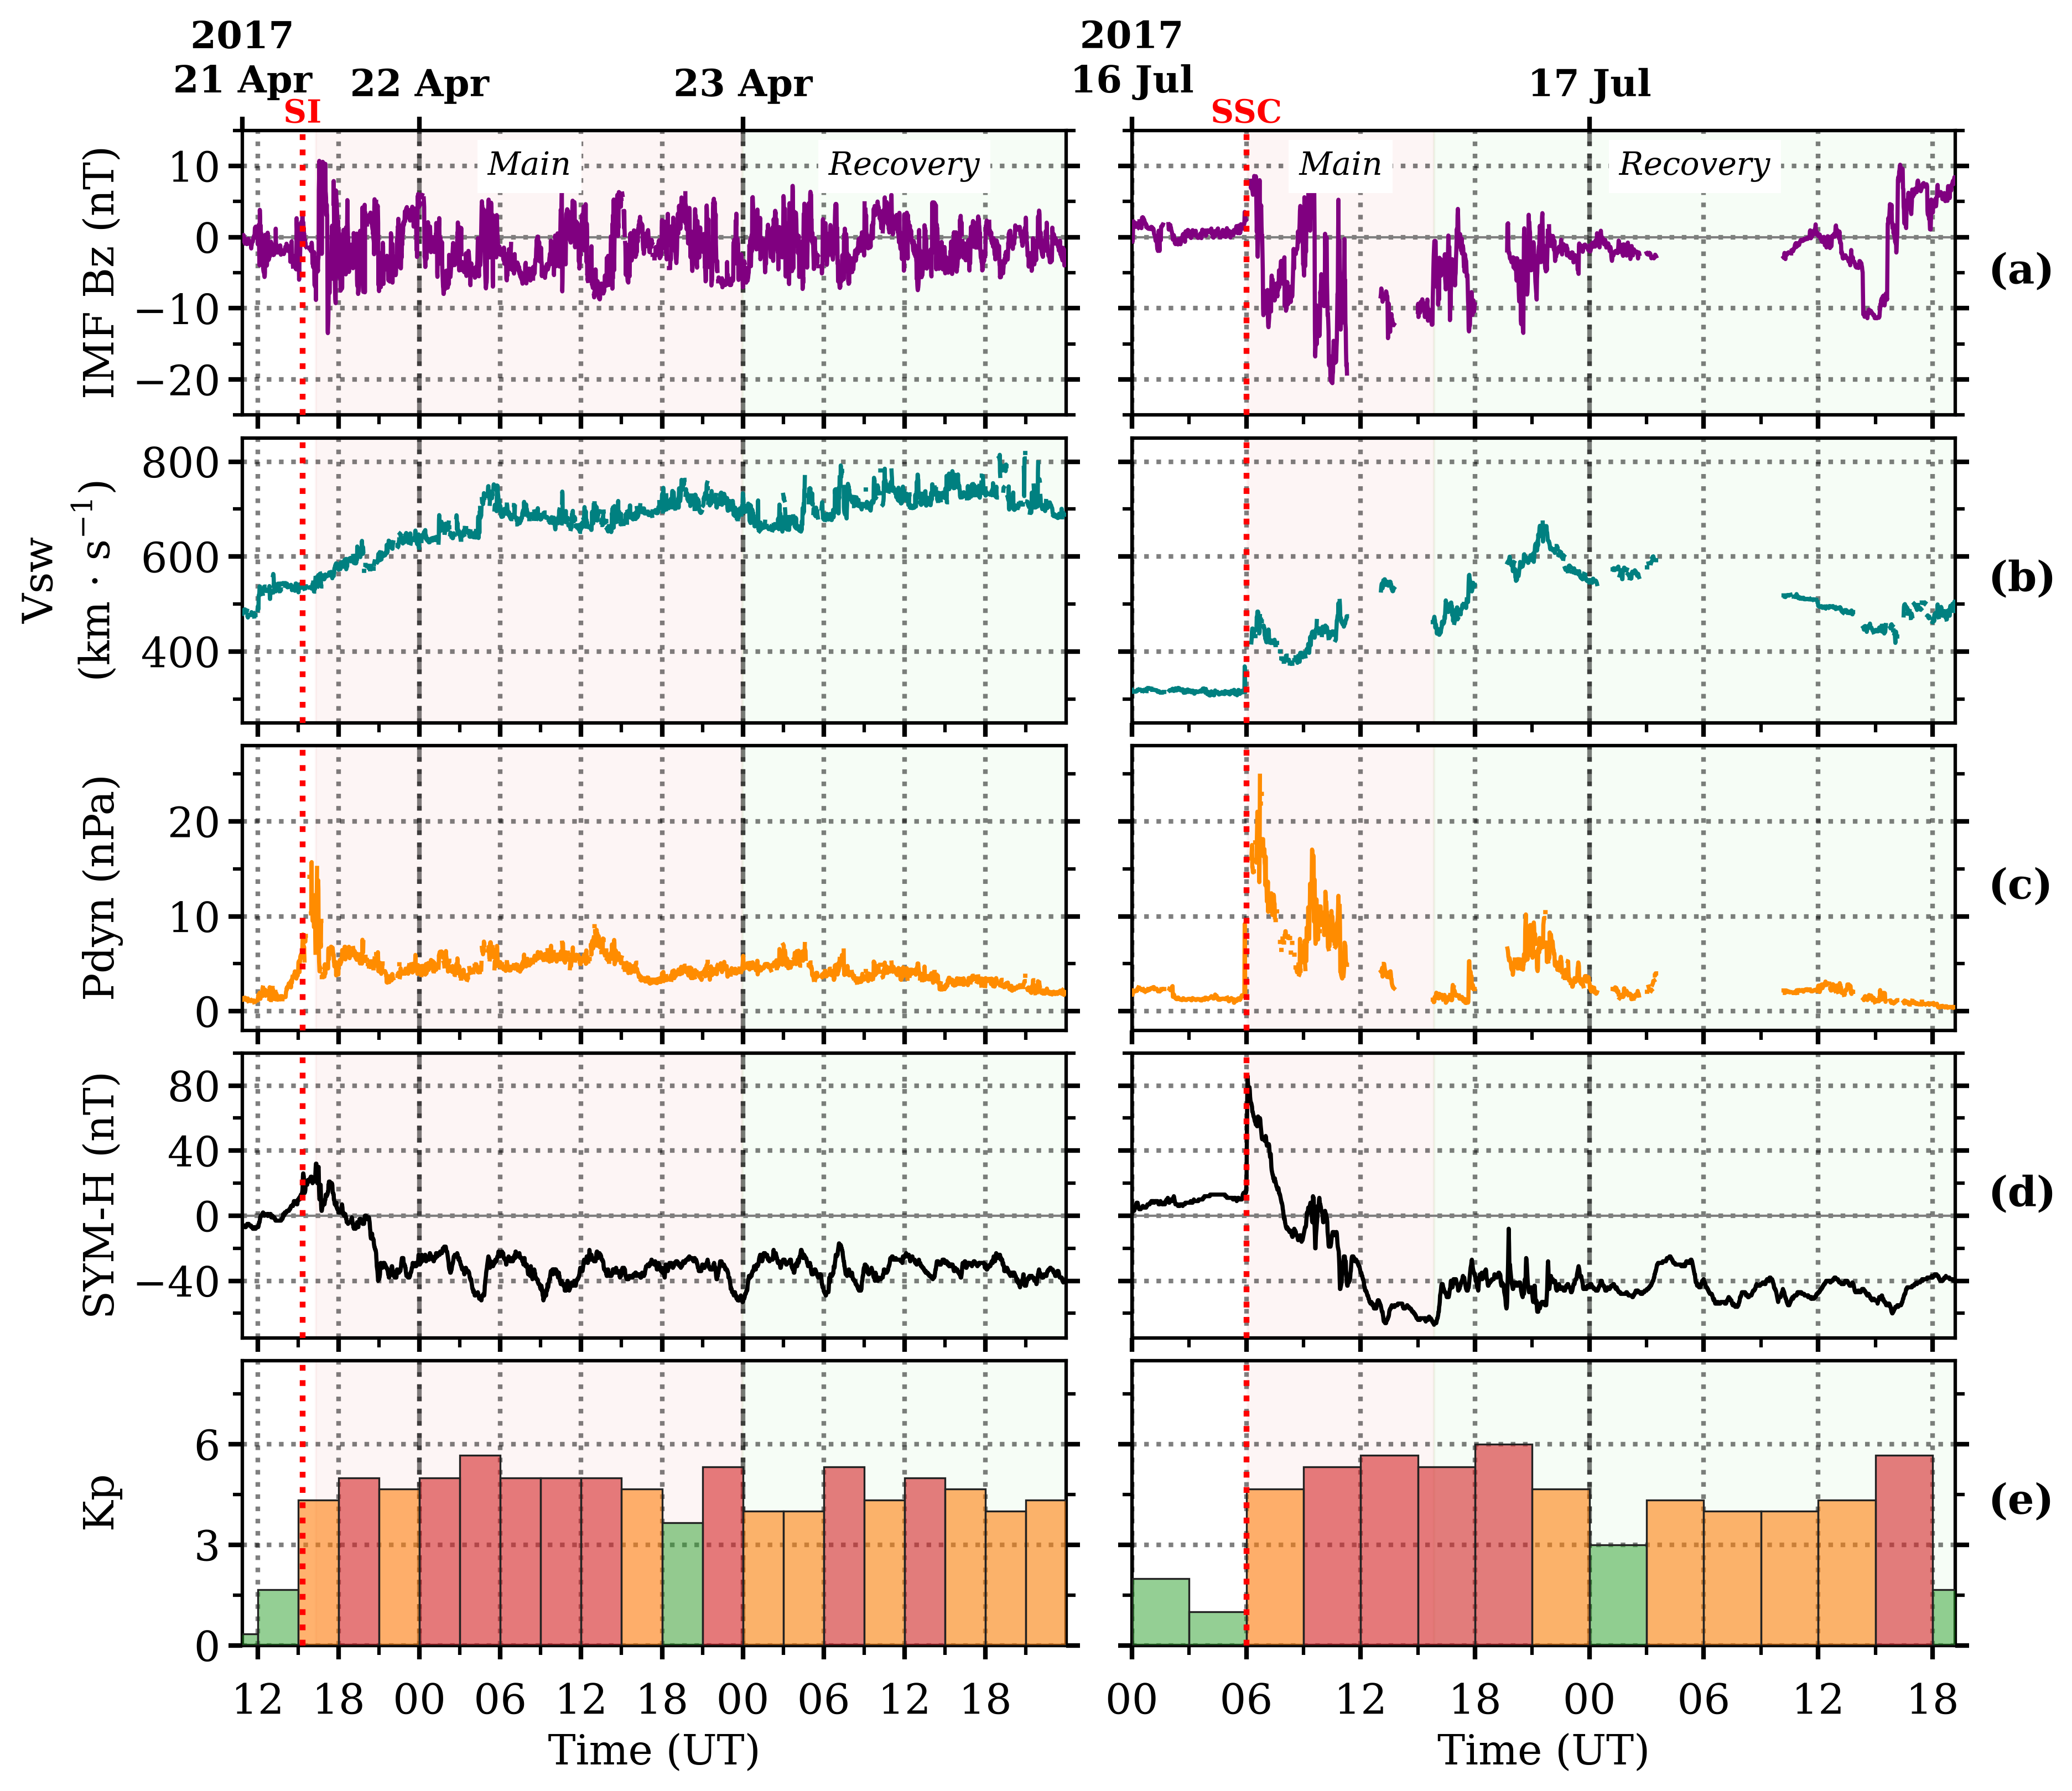

In [80]:
# Interplanetary parameters (OMNIWeb) and Kp for each event, with the storm phases and the SI/SSC onset

# Rows: name of the column, y label, color, y limits and major tick step
rows = [
    ["Bz", "IMF Bz (nT)", "purple", (-25, 15), 10],
    ["Speed", "Vsw\n(km $\\cdot$ s$^{-1}$)", "teal", (250, 850), 200],
    ["Pressure", "Pdyn (nPa)", "darkorange", (-2, 28), 10],
    ["SYM_H", "SYM-H (nT)", "black", (-75, 100), 40],
    ["Kp", "Kp", None, (0, 8.5), 3],
]
letters = ["a", "b", "c", "d", "e"]
n_rows = len(rows)
n_events = len(events)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_events, figsize=(6 * n_events, 11), sharex="col", sharey="row", squeeze=False, dpi=300)

for col in range(n_events):
    event = events[col]
    plot_start = event["exposure_start"]
    plot_end = event["exposure_end"]
    midnights = pd.date_range(start=plot_start.normalize(), end=plot_end.normalize() + pd.Timedelta(days=1), freq="D")

    # Read the OMNIWeb file (7 header lines): year, day of year, hour, minute, Bz, speed, pressure, SYM-H
    df_omni = pd.read_csv(omniweb_files[col], skiprows=7, sep=r"\s+", header=None,
                          names=["year", "doy", "hour", "minute", "Bz", "Speed", "Pressure", "SYM_H"])
    df_omni["datetime"] = (pd.to_datetime(df_omni["year"].astype(str), format="%Y")
                           + pd.to_timedelta(df_omni["doy"] - 1, unit="D")
                           + pd.to_timedelta(df_omni["hour"], unit="h")
                           + pd.to_timedelta(df_omni["minute"], unit="m"))

    # OMNIWeb missing-data codes become NaN
    df_omni.loc[df_omni["Bz"] == 9999.99, "Bz"] = np.nan
    df_omni.loc[df_omni["Speed"] == 99999.9, "Speed"] = np.nan
    df_omni.loc[df_omni["Pressure"] == 99.99, "Pressure"] = np.nan
    df_omni.loc[df_omni["SYM_H"] == 99999, "SYM_H"] = np.nan

    in_window = (df_omni["datetime"] >= plot_start) & (df_omni["datetime"] <= plot_end)
    df_omni = df_omni[in_window]

    # Read the Kp file (1 header line): year, day of year, hour, minute, Kp (one value every 3 h)
    df_kp = pd.read_csv(kp_files[col], skiprows=1, sep=r"\s+", header=None, names=["year", "doy", "hour", "minute", "Kp"])
    df_kp["datetime"] = (pd.to_datetime(df_kp["year"].astype(str), format="%Y")
                         + pd.to_timedelta(df_kp["doy"] - 1, unit="D")
                         + pd.to_timedelta(df_kp["hour"], unit="h")
                         + pd.to_timedelta(df_kp["minute"], unit="m"))

    # keep the 3-h intervals that overlap the window
    in_window = (df_kp["datetime"] + pd.Timedelta(hours=3) > plot_start) & (df_kp["datetime"] <= plot_end)
    df_kp = df_kp[in_window]

    for r in range(n_rows):
        ax = axes[r, col]
        column_name = rows[r][0]
        y_label = rows[r][1]
        line_color = rows[r][2]
        y_limits = rows[r][3]
        y_step = rows[r][4]

        # Storm phases: main (light red) and recovery (light green)
        ax.axvspan(event["main_start"], event["recovery_start"], color="lightcoral", alpha=0.08, zorder=0)
        ax.axvspan(event["recovery_start"], plot_end, color="lightgreen", alpha=0.08, zorder=0)
        if r == 0:
            main_middle = event["main_start"] + (event["recovery_start"] - event["main_start"]) / 2
            recovery_middle = event["recovery_start"] + (plot_end - event["recovery_start"]) / 2
            ax.text(main_middle, 0.93, "Main", transform=ax.get_xaxis_transform(), fontsize=14, style="italic",
                    fontdict=font_props, va="top", ha="center", zorder=20, backgroundcolor="white")
            ax.text(recovery_middle, 0.93, "Recovery", transform=ax.get_xaxis_transform(), fontsize=14, style="italic",
                    fontdict=font_props, va="top", ha="center", zorder=20, backgroundcolor="white")

        # Data: lines for the OMNIWeb parameters, 3-h bars for Kp (green < 4, orange = 4, red >= 5)
        if column_name == "Kp":
            bar_colors = []
            for kp in df_kp["Kp"]:
                if kp < 4:
                    bar_colors.append((0.17, 0.63, 0.17, 0.5))
                elif kp < 5:
                    bar_colors.append((1.0, 0.5, 0.05, 0.6))
                else:
                    bar_colors.append((0.84, 0.15, 0.16, 0.6))
            bar_centers = df_kp["datetime"] + pd.Timedelta(hours=1.5)
            ax.bar(bar_centers, df_kp["Kp"], width=3.0 / 24.0, color=bar_colors, align="center", zorder=3, edgecolor="#222222", linewidth=0.8)
        else:
            ax.plot(df_omni["datetime"], df_omni[column_name], color=line_color, linewidth=1.8, zorder=5)

        # Zero line in the Bz and SYM-H panels
        if column_name == "Bz" or column_name == "SYM_H":
            ax.axhline(0, color="gray", linestyle="-", linewidth=1.0, zorder=2)

        # SI/SSC onset: red dotted vertical line, with its name on top
        ax.axvline(event["onset"], color="red", linestyle=":", linewidth=2.5, zorder=15)
        if r == 0:
            ax.text(event["onset"], 1.0, event["onset_label"], transform=ax.get_xaxis_transform(), fontsize=14,
                    fontdict=font_props, fontweight="bold", va="bottom", ha="center", color="red", zorder=25)

        # Y axis
        ax.set_ylim(y_limits)
        ax.yaxis.set_major_locator(MultipleLocator(y_step))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.tick_params(axis="y", which="major", direction="out", length=6, width=2.0, colors="black", left=True, right=True, labelsize=18)
        ax.tick_params(axis="y", which="minor", direction="out", length=4, width=1.5, colors="black", left=True, right=True)
        if col > 0:
            ax.tick_params(axis="y", labelleft=False, labelright=False)
        else:
            ax.set_ylabel(y_label, fontsize=18, color="black", fontdict=font_props)
            for label in ax.get_yticklabels():
                label.set_fontproperties(font_props)
                label.set_fontsize(18)

        ax.grid(True, which="major", axis="both", color="black", alpha=0.5, linestyle=":", linewidth=2)

        # Letters (a)-(e) only in the last column, on the right side
        if col == n_events - 1:
            ax.text(1.04, 0.5, "(" + letters[r] + ")", transform=ax.transAxes, fontsize=18, fontweight="bold",
                    fontdict=font_props, va="center", ha="left", zorder=20, color="black")

        # Dashed vertical line at each midnight inside the window
        for midnight in midnights:
            if plot_start <= midnight <= plot_end:
                ax.axvline(midnight, color="black", alpha=0.5, linestyle="--", linewidth=2.0, zorder=2)

        ax.set_axisbelow(True)
        ax.set_xlim(plot_start, plot_end)
        ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[3, 9, 15, 21]))
        for spine in ax.spines.values():
            spine.set_linewidth(1.5)
            spine.set_color("black")
        if r < n_rows - 1:
            ax.tick_params(axis="x", which="major", direction="out", length=6, width=2.0, colors="black", labelbottom=False)
            ax.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5, colors="black", labelbottom=False)

    # Bottom x axis: hours
    ax_bottom = axes[-1, col]
    ax_bottom.set_xlabel("Time (UT)", fontsize=18, color="black", fontdict=font_props)
    ax_bottom.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
    ax_bottom.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
    ax_bottom.tick_params(axis="x", which="major", direction="out", length=6, width=2.0, pad=10, colors="black")
    ax_bottom.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5, colors="black")
    for label in ax_bottom.get_xticklabels():
        label.set_fontproperties(font_props)
        label.set_fontsize(18)

    # Top x axis: one date label at the first minute of each day
    day_starts = []
    for t in df_omni["datetime"]:
        if len(day_starts) == 0 or t.date() != day_starts[-1].date():
            day_starts.append(t)
    day_labels = []
    for i in range(len(day_starts)):
        if i == 0:
            day_labels.append(day_starts[i].strftime("%Y\n%d %b"))
        else:
            day_labels.append(day_starts[i].strftime("%d %b"))
    ax_top = axes[0, col].secondary_xaxis("top")
    ax_top.set_xticks(day_starts)
    ax_top.set_xticklabels(day_labels)
    ax_top.tick_params(axis="x", direction="out", length=6, width=2.0, pad=5, colors="black")
    for label in ax_top.get_xticklabels():
        label.set_fontproperties(font_props)
        label.set_fontsize(16)
        label.set_fontweight("bold")
        label.set_ha("center")

fig.align_ylabels(axes[:, 0])
plt.subplots_adjust(hspace=0.08, wspace=0.08, top=0.90, bottom=0.07, left=0.08, right=0.94)

fig.savefig(figures_folder + "/Fig_interplanetary_parameters.png", dpi=300, bbox_inches="tight")
plt.show()

## **Geomagnetic and geoelectric field**

ΔH and dH/dt at MAN and the magnitude of the geoelectric field in the Solimões (E_SB) and Amazonas (E_AB) basins, for each event (columns), inside the exposure window. The shading marks the main and recovery phases, as in the previous figure, and the vertical dashed lines mark midnight UT.

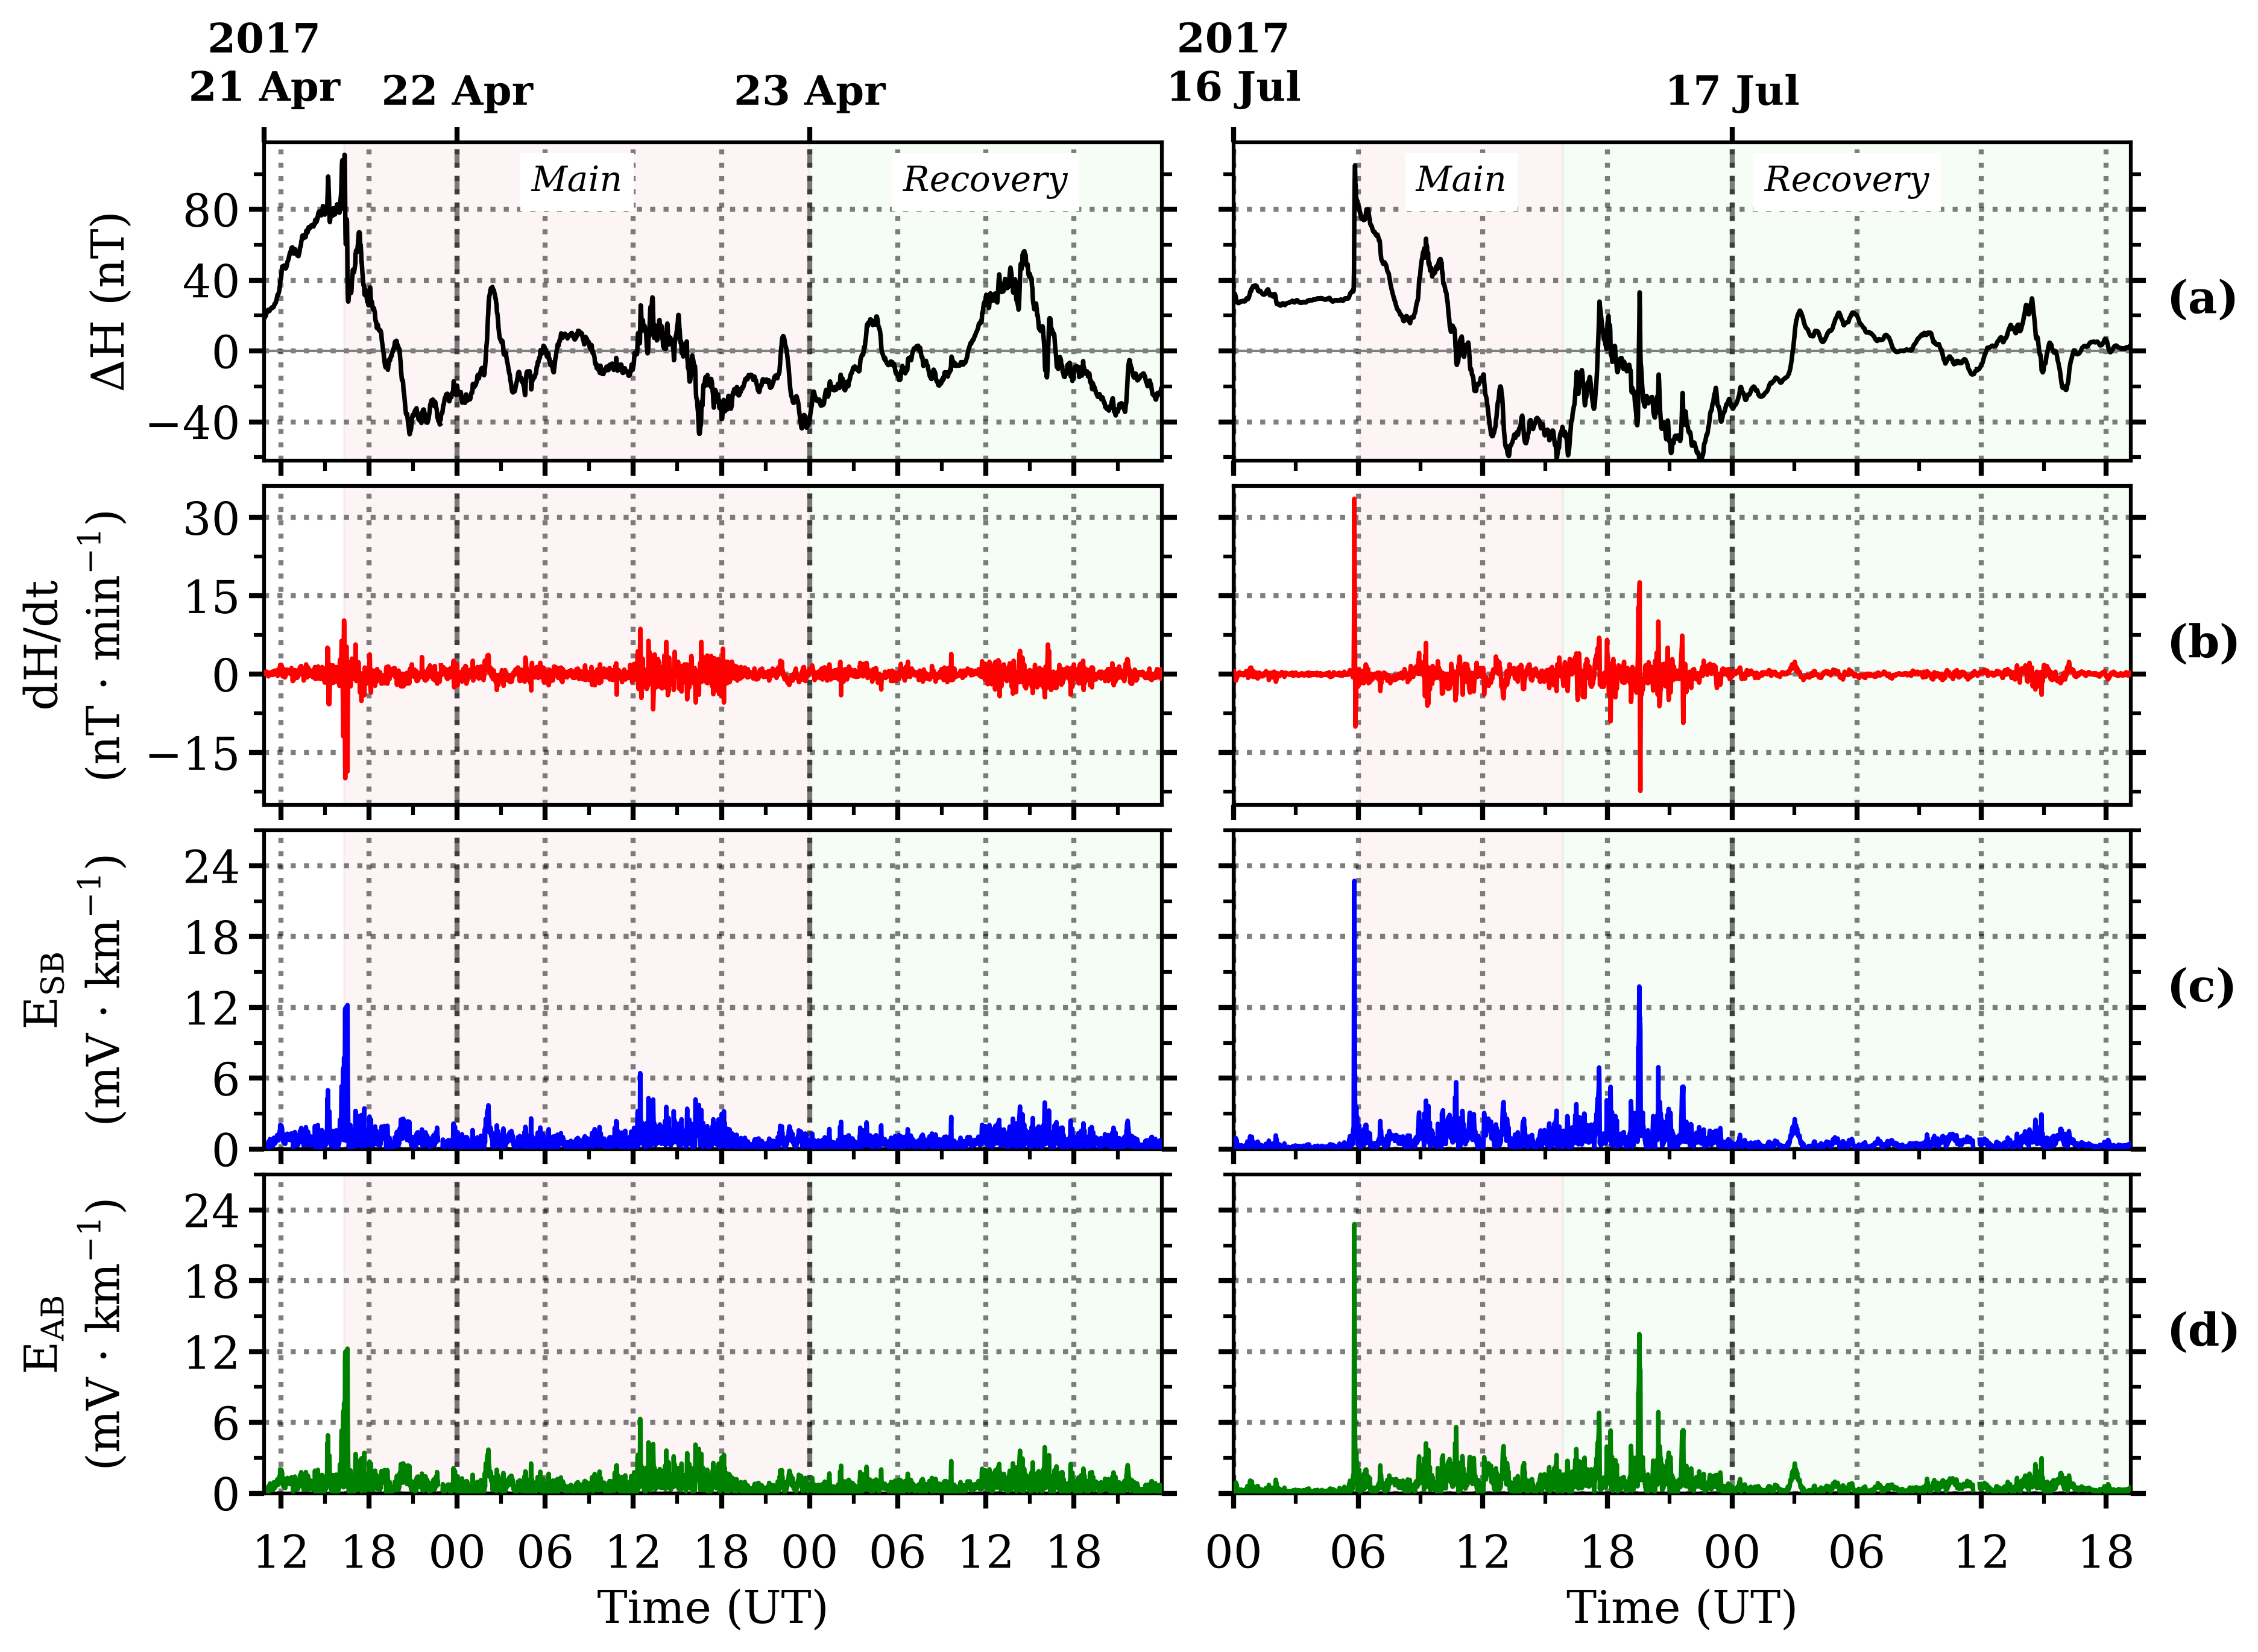

In [81]:
# deltaH, dH/dt and geoelectric field magnitude in each basin, for each event, with the storm phases

# Rows: name of the column in the CSV, y label, color, y limits and major tick step
rows = [
    ["deltaH", "$\\Delta$H (nT)", "black", (-62, 118), 40],
    ["dH_dt", "dH/dt\n(nT $\\cdot$ min$^{-1}$)", "red", (-25, 36), 15],
    ["E_solimoes_Vkm", "E$_{\\mathrm{SB}}$\n(mV $\\cdot$ km$^{-1}$)", "blue", (0, 27), 6],
    ["E_amazonas_Vkm", "E$_{\\mathrm{AB}}$\n(mV $\\cdot$ km$^{-1}$)", "green", (0, 27), 6],
]
letters = ["a", "b", "c", "d"]
n_rows = len(rows)
n_events = len(events)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_events, figsize=(6 * n_events, 9), sharex="col", sharey="row", squeeze=False, dpi=300)

for col in range(n_events):
    event = events[col]
    event_id = event["id"]

    # Electric field CSV of this event, cut to the exposure window
    df_field = pd.read_csv(output_folder + "/electric_field_event_" + str(event_id) + ".csv")
    df_field["datetime"] = pd.to_datetime(df_field["datetime"])
    in_window = (df_field["datetime"] >= event["exposure_start"]) & (df_field["datetime"] <= event["exposure_end"])
    df_field = df_field[in_window]

    plot_start = event["exposure_start"]
    plot_end = event["exposure_end"]
    midnights = pd.date_range(start=plot_start.normalize(), end=plot_end.normalize() + pd.Timedelta(days=1), freq="D")

    for r in range(n_rows):
        ax = axes[r, col]
        column_name = rows[r][0]
        y_label = rows[r][1]
        line_color = rows[r][2]
        y_limits = rows[r][3]
        y_step = rows[r][4]

        # Storm phases: main (light red) and recovery (light green)
        ax.axvspan(event["main_start"], event["recovery_start"], color="lightcoral", alpha=0.08, zorder=0)
        ax.axvspan(event["recovery_start"], plot_end, color="lightgreen", alpha=0.08, zorder=0)
        if r == 0:
            main_middle = event["main_start"] + (event["recovery_start"] - event["main_start"]) / 2
            recovery_middle = event["recovery_start"] + (plot_end - event["recovery_start"]) / 2
            ax.text(main_middle, 0.93, "Main", transform=ax.get_xaxis_transform(), fontsize=14, style="italic",
                    fontdict=font_props, va="top", ha="center", zorder=20, backgroundcolor="white")
            ax.text(recovery_middle, 0.93, "Recovery", transform=ax.get_xaxis_transform(), fontsize=14, style="italic",
                    fontdict=font_props, va="top", ha="center", zorder=20, backgroundcolor="white")

        # Data: the electric field goes from V/km to mV/km
        values = df_field[column_name]
        if column_name.startswith("E_"):
            values = values * 1000
        ax.plot(df_field["datetime"], values, color=line_color, linewidth=1.8, zorder=5)

        # Zero line in the deltaH and dH/dt panels
        if r < 2:
            ax.axhline(0, color="gray", linestyle="-", linewidth=1.0, zorder=2)

        # Y axis
        ax.set_ylim(y_limits)
        ax.yaxis.set_major_locator(MultipleLocator(y_step))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.tick_params(axis="y", which="major", direction="out", length=6, width=2.0, colors="black", left=True, right=True, labelsize=18)
        ax.tick_params(axis="y", which="minor", direction="out", length=4, width=1.5, colors="black", left=True, right=True)
        if col > 0:
            ax.tick_params(axis="y", labelleft=False, labelright=False)
        else:
            ax.set_ylabel(y_label, fontsize=18, color="black", fontdict=font_props)
            for label in ax.get_yticklabels():
                label.set_fontproperties(font_props)
                label.set_fontsize(18)

        ax.grid(True, which="major", axis="both", color="black", alpha=0.5, linestyle=":", linewidth=2)

        # Letters (a)-(d) only in the last column, on the right side
        if col == n_events - 1:
            ax.text(1.04, 0.5, "(" + letters[r] + ")", transform=ax.transAxes, fontsize=18, fontweight="bold",
                    fontdict=font_props, va="center", ha="left", zorder=20, color="black")

        # Dashed vertical line at each midnight inside the window
        for midnight in midnights:
            if plot_start <= midnight <= plot_end:
                ax.axvline(midnight, color="black", alpha=0.5, linestyle="--", linewidth=2.0, zorder=2)

        ax.set_axisbelow(True)
        ax.set_xlim(plot_start, plot_end)
        ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[3, 9, 15, 21]))
        for spine in ax.spines.values():
            spine.set_linewidth(1.5)
            spine.set_color("black")
        if r < n_rows - 1:
            ax.tick_params(axis="x", which="major", direction="out", length=6, width=2.0, colors="black", labelbottom=False)
            ax.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5, colors="black", labelbottom=False)

    # Bottom x axis: hours
    ax_bottom = axes[-1, col]
    ax_bottom.set_xlabel("Time (UT)", fontsize=18, color="black", fontdict=font_props)
    ax_bottom.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
    ax_bottom.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
    ax_bottom.tick_params(axis="x", which="major", direction="out", length=6, width=2.0, pad=10, colors="black")
    ax_bottom.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5, colors="black")
    for label in ax_bottom.get_xticklabels():
        label.set_fontproperties(font_props)
        label.set_fontsize(18)

    # Top x axis: one date label at the first minute of each day
    day_starts = []
    for t in df_field["datetime"]:
        if len(day_starts) == 0 or t.date() != day_starts[-1].date():
            day_starts.append(t)
    day_labels = []
    for i in range(len(day_starts)):
        if i == 0:
            day_labels.append(day_starts[i].strftime("%Y\n%d %b"))
        else:
            day_labels.append(day_starts[i].strftime("%d %b"))
    ax_top = axes[0, col].secondary_xaxis("top")
    ax_top.set_xticks(day_starts)
    ax_top.set_xticklabels(day_labels)
    ax_top.tick_params(axis="x", direction="out", length=6, width=2.0, pad=5, colors="black")
    for label in ax_top.get_xticklabels():
        label.set_fontproperties(font_props)
        label.set_fontsize(16)
        label.set_fontweight("bold")
        label.set_ha("center")

fig.align_ylabels(axes[:, 0])
plt.subplots_adjust(hspace=0.08, wspace=0.08, top=0.90, bottom=0.07, left=0.08, right=0.94)

fig.savefig(figures_folder + "/Fig_geoelectric_field.png", dpi=300, bbox_inches="tight")
plt.show()

## **PSP exposure map**

Nodes and minutes with PSP above the -850 mV protection threshold (red marks), with the distance along the pipeline on the vertical axis and time (UT) on the horizontal axis, for each event (columns) and terminating impedance Zt (rows). The horizontal dash-dotted and dashed lines mark the basin and pipeline-section boundaries, respectively, and the vertical dashed lines mark midnight UT.

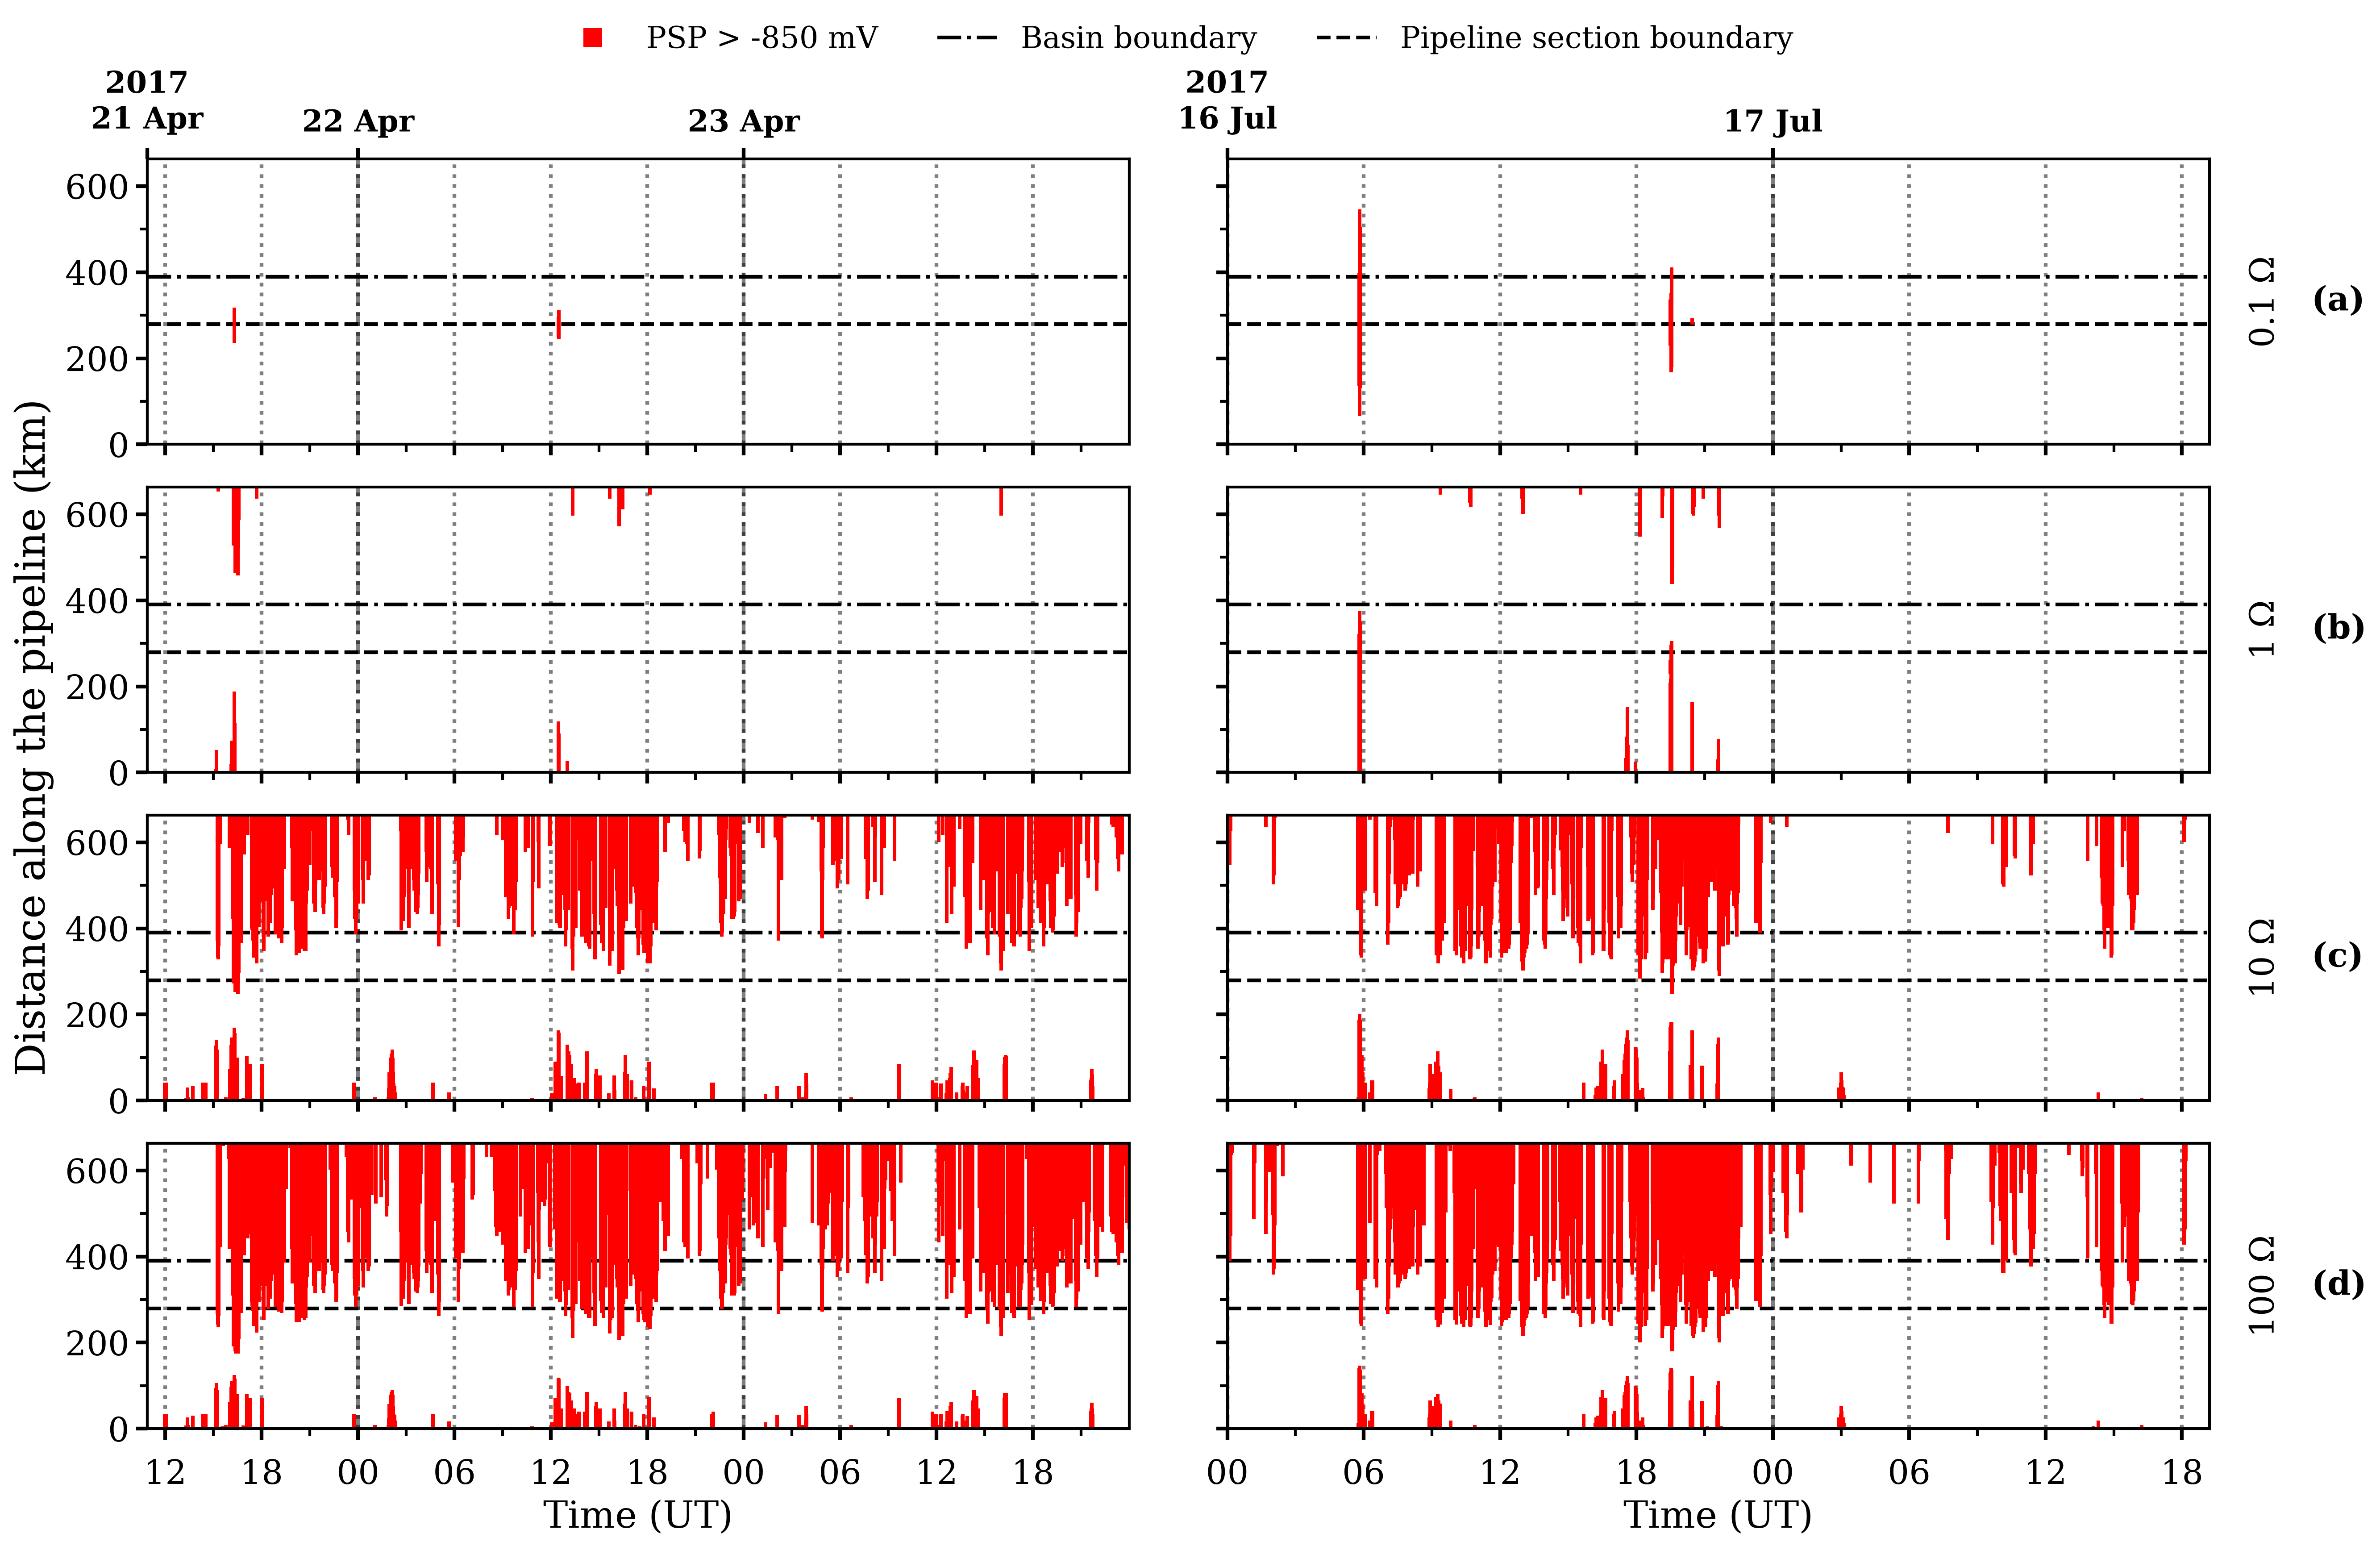

In [82]:
output_path = figures_folder + "/Fig5_psp_exposure.png"
letters = ["a", "b", "c", "d"]

# Distance along the pipeline (km) of every node, and the km of the basin and pipeline-section boundaries
df_circuit = pd.read_csv(pipeline_circuit_path)
n_points = len(df_circuit)

distance_km = np.zeros(n_points)
for i in range(1, n_points):
    distance_km[i] = distance_km[i - 1] + df_circuit["prev_dist"].iloc[i]

basin_line_km = None
pipeline_line_km = None
for i in range(1, n_points):
    if df_circuit["Basin"].iloc[i] != df_circuit["Basin"].iloc[i - 1]:
        basin_line_km = distance_km[i]
    if df_circuit["Pipeline"].iloc[i] != df_circuit["Pipeline"].iloc[i - 1]:
        pipeline_line_km = distance_km[i]

# Figure (margins in absolute inches, as in the other figures)
n_events = len(events)
n_rows = len(zt_values)
figure_width_in = 9 * n_events
side_margin_in = 1.3
left_frac = side_margin_in / figure_width_in
right_frac = 1 - (side_margin_in / figure_width_in)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_events, figsize=(figure_width_in, 12), sharex="col", squeeze=False, dpi=300)

for col in range(n_events):
    event = events[col]
    event_folder_path = output_folder + "/psp_results/event_" + str(event["id"])
    plot_start = event["exposure_start"]
    plot_end = event["exposure_end"]

    # minutes of the exposure window
    df_zt_first = pd.read_csv(event_folder_path + "/psp_zt_" + str(zt_values[0]) + ".csv")
    all_time_columns = df_zt_first.columns[1:]
    all_time_values = pd.to_datetime(all_time_columns)

    window_mask = (all_time_values >= plot_start) & (all_time_values <= plot_end)
    time_columns = all_time_columns[window_mask]
    time_values = all_time_values[window_mask]

    midnights = pd.date_range(start=plot_start.normalize(), end=plot_end.normalize() + pd.Timedelta(days=1), freq="D")

    for row in range(n_rows):
        zt = zt_values[row]
        ax = axes[row, col]

        df_psp = pd.read_csv(event_folder_path + "/psp_zt_" + str(zt) + ".csv")
        psp_matrix = df_psp[time_columns].values

        # Red marks: PSP above the threshold (NaN counts as not above)
        risk_times = []
        risk_km = []
        for node in range(psp_matrix.shape[0]):
            for minute in range(psp_matrix.shape[1]):
                if psp_matrix[node, minute] > threshold_V:
                    risk_times.append(time_values[minute])
                    risk_km.append(distance_km[node])
        ax.scatter(risk_times, risk_km, s=4, marker="s", color="red", linewidths=0, zorder=5)

        ax.axhline(y=basin_line_km, color="black", linestyle="-.", linewidth=2.0, zorder=2)
        ax.axhline(y=pipeline_line_km, color="black", linestyle="--", linewidth=2.0, zorder=2)

        # Distance axis (left only)
        ax.set_ylim(distance_km.min(), distance_km.max())
        ax.yaxis.set_major_locator(MultipleLocator(200))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.tick_params(axis="y", which="major", labelsize=18, direction="out", length=6, width=2.0, colors="black", left=True, right=False, labelleft=(col == 0), labelright=False)
        ax.tick_params(axis="y", which="minor", direction="out", length=4, width=1.5, colors="black", left=True, right=False)
        ax.set_axisbelow(True)
        ax.grid(True, axis="x", color="black", alpha=0.5, linestyle=":", linewidth=2, zorder=1)

        for sp in ax.spines.values():
            sp.set_linewidth(1.5)
            sp.set_color("black")
            sp.set_zorder(10)

        # Impedance and panel letter, on the right side of the last column
        if col == n_events - 1:
            impedance_text = str(zt) + " $\\Omega$"
            letter_text = "$\\mathbf{(" + letters[row] + ")}$"
            ax.annotate(impedance_text, xy=(1, 0.5), xycoords="axes fraction",
                        xytext=(30, 0), textcoords="offset points",
                        fontsize=18, family="serif", va="center", ha="center", color="black", zorder=30,
                        rotation="vertical")
            ax.annotate(letter_text, xy=(1, 0.5), xycoords="axes fraction",
                        xytext=(55, 0), textcoords="offset points",
                        fontsize=18, family="serif", va="center", ha="left", color="black", zorder=30)

        ax.set_xlim(plot_start, plot_end)
        ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[3, 9, 15, 21]))
        ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))

        for mn in midnights:
            if plot_start <= mn <= plot_end:
                ax.axvline(mn, color="black", alpha=0.5, linestyle="--", linewidth=2.0, zorder=2)

        ax.tick_params(axis="x", which="major", direction="out", length=6, width=2.0, colors="black", labelbottom=(row == n_rows - 1))
        ax.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5, colors="black", labelbottom=False)

    # Bottom axis: hours (UT)
    ax_bottom = axes[-1, col]
    ax_bottom.set_xlabel("Time (UT)", fontsize=20, color="black", fontdict=font_props)
    ax_bottom.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
    ax_bottom.tick_params(axis="x", which="major", pad=10, labelsize=18)
    for label in ax_bottom.get_xticklabels():
        label.set_fontproperties(font_props)
        label.set_fontsize(18)

    # Top axis: dates (first minute of each day; the year only on the first one)
    start_of_days = []
    for t in time_values:
        if len(start_of_days) == 0 or t.date() != start_of_days[-1].date():
            start_of_days.append(t)

    tick_labels = []
    for i in range(len(start_of_days)):
        day = start_of_days[i]
        if i == 0:
            tick_labels.append(str(day.year) + "\n" + day.strftime("%d %b"))
        else:
            tick_labels.append(day.strftime("%d %b"))

    ax_top = axes[0, col].secondary_xaxis("top")
    ax_top.set_xticks(start_of_days)
    ax_top.set_xticklabels(tick_labels)
    ax_top.tick_params(axis="x", direction="out", length=6, width=2.0, pad=5, colors="black")
    for label in ax_top.get_xticklabels():
        label.set_fontproperties(font_props)
        label.set_fontsize(16)
        label.set_fontweight("bold")
        label.set_ha("center")

# Global label (distance only; the node axis was removed)
fig.text(left_frac * 0.35, 0.49, "Distance along the pipeline (km)", fontsize=22, color="black", fontdict=font_props, va="center", ha="center", rotation="vertical")

# Global legend
legend_elements = [
    Line2D([0], [0], marker="s", color="w", markerfacecolor="red", markeredgecolor="none", markersize=10, label="PSP > -850 mV"),
    Line2D([0], [0], color="black", linestyle="-.", linewidth=2.0, label="Basin boundary"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=2.0, label="Pipeline section boundary"),
]
fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=3, frameon=False,
           prop={"family": "serif", "size": 16})

plt.subplots_adjust(left=left_frac, right=right_frac, bottom=0.06, top=0.85, wspace=0.10, hspace=0.15)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

## **PSP profiles at the instant of largest |dH/dt|**

PSP along the pipeline at the instant of largest |dH/dt| at MAN inside the exposure window, for each event (columns) and terminating impedance Zt (colors). The gray line marks the -1025 mV cathodic protection baseline, the dotted line the -850 mV protection threshold, and the dash-dotted and dashed lines the basin and pipeline-section boundaries, respectively.

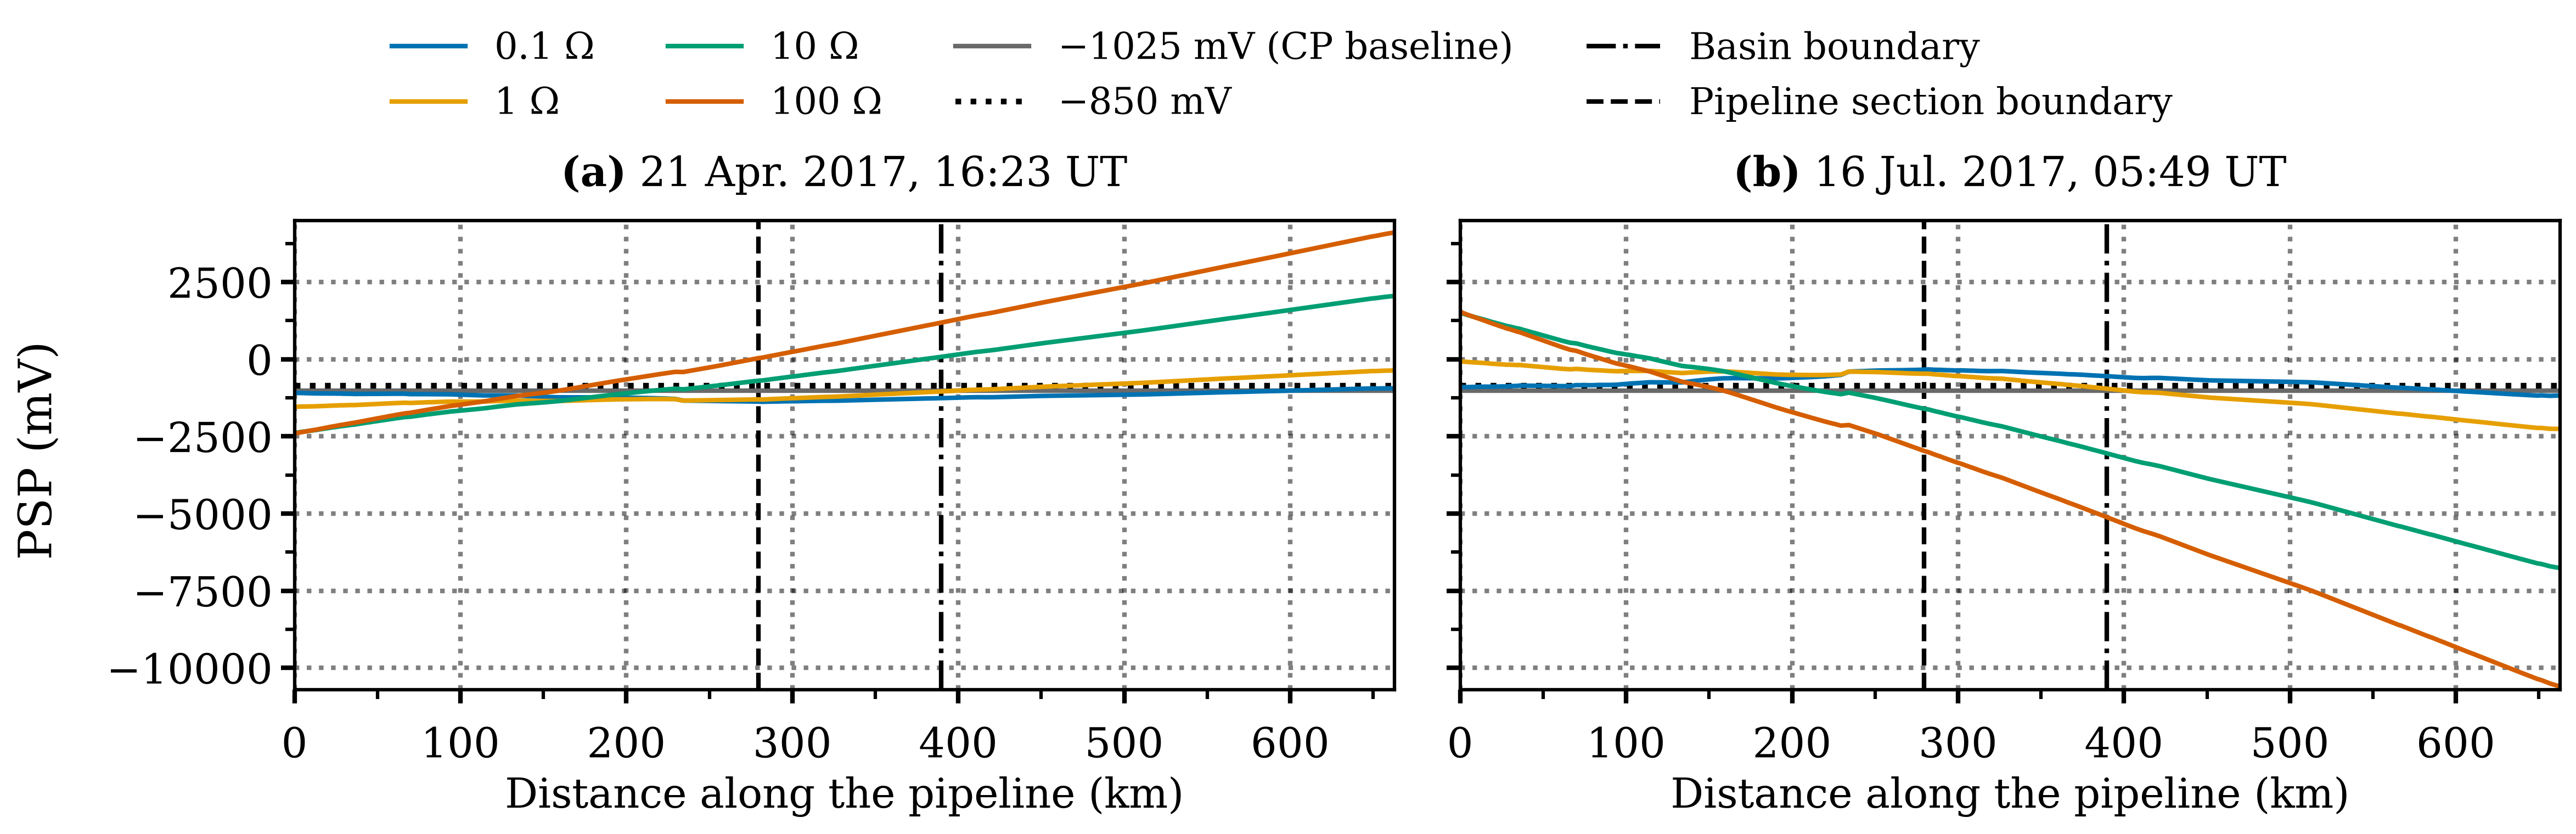

In [83]:
# PSP profiles along the pipeline at the instant of largest |dH/dt| at MAN
# Distance along the pipeline (km) and boundaries
df_circuit = pd.read_csv(pipeline_circuit_path)
n_points = len(df_circuit)

distance_km = np.zeros(n_points)
for i in range(1, n_points):
    distance_km[i] = distance_km[i - 1] + df_circuit["prev_dist"].iloc[i]

basin_line_km = None
pipeline_line_km = None
for i in range(1, n_points):
    if df_circuit["Basin"].iloc[i] != df_circuit["Basin"].iloc[i - 1]:
        basin_line_km = distance_km[i]
    if df_circuit["Pipeline"].iloc[i] != df_circuit["Pipeline"].iloc[i - 1]:
        pipeline_line_km = distance_km[i]

# H at MAN (1-min), from all magnetometer files
times_H = []
values_H = []
for file_name in sorted(os.listdir(magnetometer_folder)):
    with open(magnetometer_folder + "/" + file_name) as f:
        lines = f.readlines()
    for line in lines[3:]:
        parts = line.split()
        if len(parts) < 7:
            continue
        times_H.append(pd.Timestamp(year=int(parts[2]), month=int(parts[1]), day=int(parts[0]), hour=int(parts[3]), minute=int(parts[4])))
        values_H.append(float(parts[6]))

df_H = pd.DataFrame({"t": times_H, "H": values_H})
df_H = df_H.drop_duplicates("t")
H = df_H.set_index("t")["H"].sort_index()

# Representative instants: same criterion in both events
# instant of the largest |dH/dt| at MAN inside the analysis window (dH/dt = difference between consecutive minutes)
instants = {}
for event in events:
    h_window = H[event["exposure_start"]:event["exposure_end"]]
    dh_abs = h_window.diff().abs()
    instants[event["id"]] = dh_abs.idxmax()

ylim_common = (-10700, 4500)
n_events = len(events)
letters = ["a", "b"]
figure_width_in = 8 * n_events
side_margin_in = 2.0
left_frac = side_margin_in / figure_width_in

fig, axes = plt.subplots(nrows=1, ncols=n_events, figsize=(figure_width_in, 5), sharey=True, squeeze=False, dpi=300)
axes = axes[0]

for k in range(n_events):
    event = events[k]
    event_id = event["id"]
    ax = axes[k]

    for zt in zt_values:
        # PSP (mV) inside the exposure window
        df = pd.read_csv(output_folder + "/psp_results/event_" + str(event_id) + "/psp_zt_" + str(zt) + ".csv")
        times = pd.to_datetime(df.columns[1:])
        in_window = (times >= event["exposure_start"]) & (times <= event["exposure_end"])
        times_window = times[in_window]
        psp_mV = 1000 * df.iloc[:, 1:].values[:, in_window]

        # minute of the representative instant
        j = int(np.argmin(np.abs(times_window - instants[event_id])))
        ax.plot(distance_km, psp_mV[:, j], color=colors[zt], linewidth=2.0, zorder=5)

    t = times_window[j]

    ax.axhline(y=baseline_mV, color="dimgray", linestyle="-", linewidth=2.0, zorder=4)
    ax.axhline(y=threshold_mV, color="black", linestyle=":", linewidth=2.5, zorder=4)
    ax.axvline(x=basin_line_km, color="black", linestyle="-.", linewidth=2.0, zorder=3)
    ax.axvline(x=pipeline_line_km, color="black", linestyle="--", linewidth=2.0, zorder=3)

    ax.set_xlim(0, distance_km[-1])
    ax.set_ylim(ylim_common)
    ax.yaxis.set_major_locator(MultipleLocator(2500))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.grid(True, axis="both", color="black", alpha=0.5, linestyle=":", linewidth=2, zorder=1)
    ax.set_axisbelow(True)

    ax.tick_params(axis="y", which="major", labelsize=18, direction="out", length=6, width=2.0, colors="black", left=True, right=False, labelleft=(k == 0))
    ax.tick_params(axis="y", which="minor", direction="out", length=4, width=1.5, colors="black", left=True, right=False)
    ax.tick_params(axis="x", which="major", labelsize=18, direction="out", length=6, width=2.0, pad=10, colors="black")
    ax.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5, colors="black")
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color("black")
        spine.set_zorder(10)
    for label in ax.get_xticklabels():
        label.set_fontproperties(font_props)
        label.set_fontsize(18)

    ax.set_xlabel("Distance along the pipeline (km)", fontsize=18, color="black", fontdict=font_props)

    # Panel title: letter and instant
    title = "$\\mathbf{(" + letters[k] + ")}$ " + t.strftime("%d %b. %Y, %H:%M") + " UT"
    ax_top = ax.secondary_xaxis("top")
    ax_top.set_xticks([])
    ax_top.tick_params(axis="x", direction="out", length=6, width=2.0, colors="black")
    ax_top.set_xlabel(title, fontsize=18, color="black", fontdict=font_props, labelpad=15)

# Global y label
fig.text(0.45 / figure_width_in, 0.42, "PSP (mV)", fontsize=20, color="black", fontdict=font_props, va="center", ha="center", rotation="vertical")

# Global legend
legend_elements = []
for zt in zt_values:
    legend_elements.append(Line2D([0], [0], color=colors[zt], linewidth=2.0, label=str(zt) + " $\\Omega$"))
legend_elements.append(Line2D([0], [0], color="dimgray", linestyle="-", linewidth=2.0, label=r"$-1025$ mV (CP baseline)"))
legend_elements.append(Line2D([0], [0], color="black", linestyle=":", linewidth=2.5, label=r"$-850$ mV"))
legend_elements.append(Line2D([0], [0], color="black", linestyle="-.", linewidth=2.0, label="Basin boundary"))
legend_elements.append(Line2D([0], [0], color="black", linestyle="--", linewidth=2.0, label="Pipeline section boundary"))
fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=4, frameon=False, prop={"family": "serif", "size": 16})

plt.subplots_adjust(left=left_frac, right=0.985, bottom=0.13, top=0.70, wspace=0.06)
fig.savefig(figures_folder + "/Fig_PSP_instant_profiles.png", dpi=300, bbox_inches="tight")

## **Corrosion Plot**

Corrosion rate (red bars, left axis) and total exposure time (blue line, right axis) of each node along the pipeline, for each event (columns) and terminating impedance Zt (rows). The orange line marks 0.025 mm·yr⁻¹, and the dash-dotted and dashed lines mark the basin and pipeline-section boundaries, respectively.

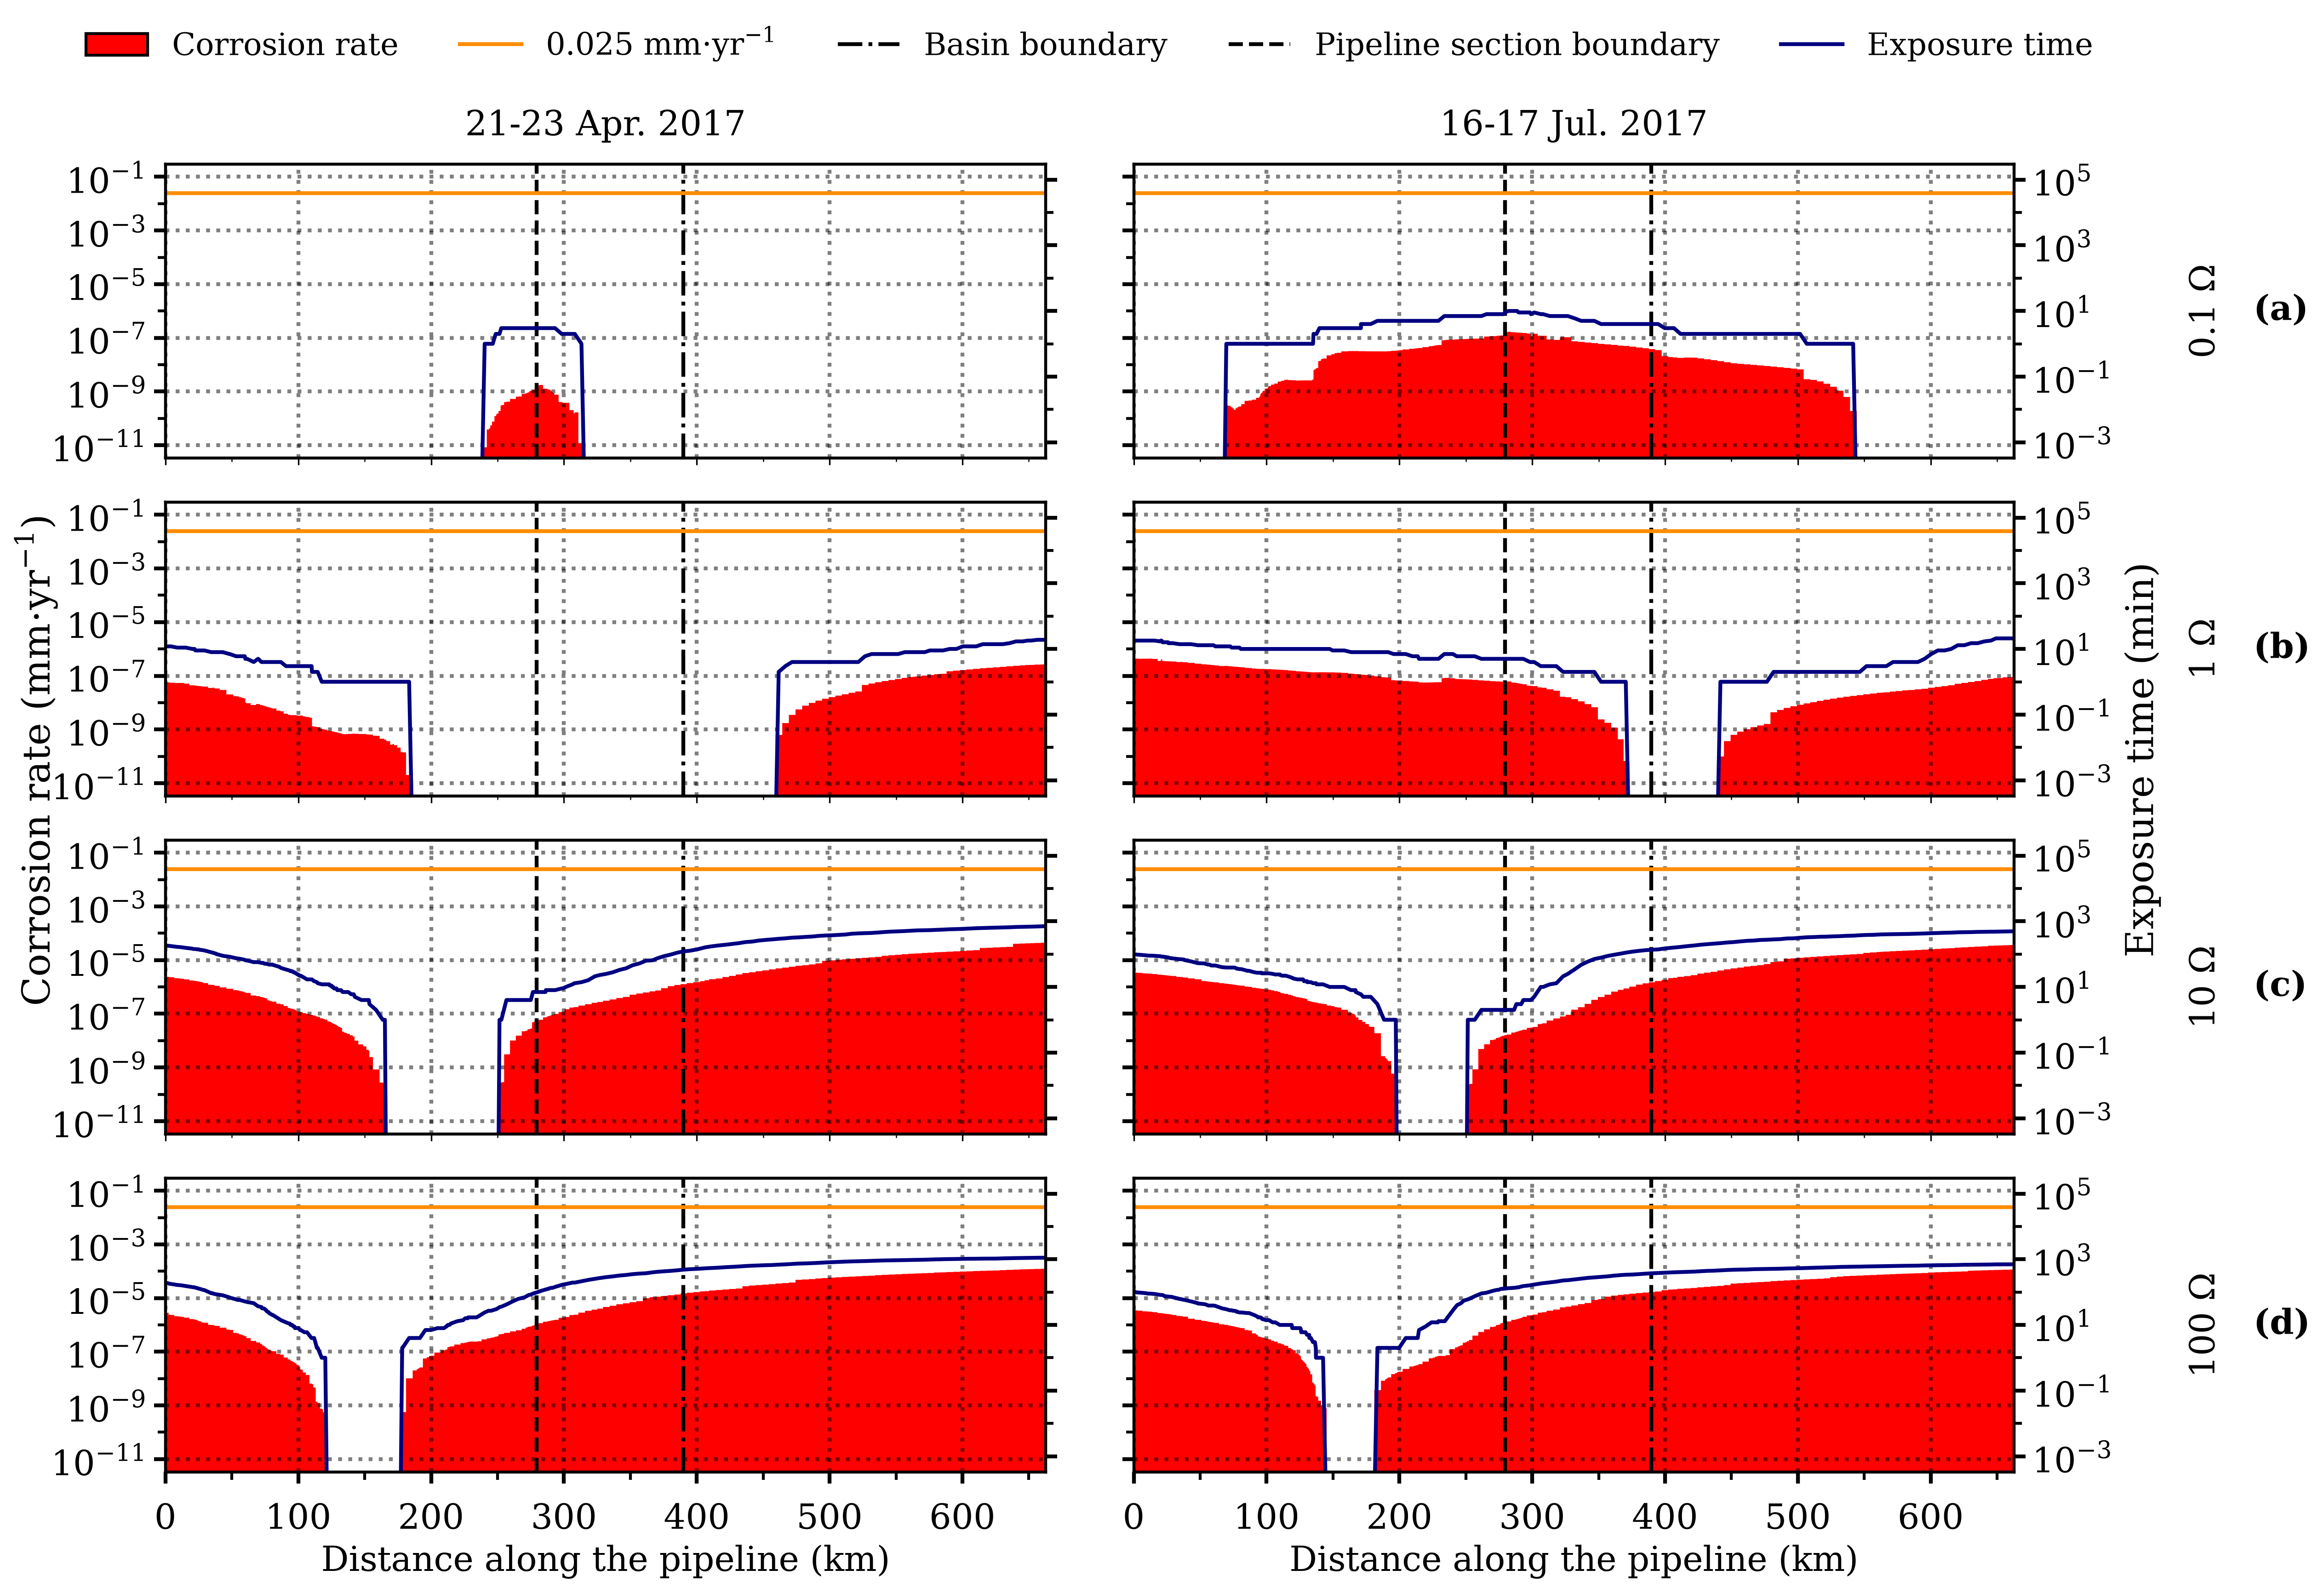

In [84]:
# Distance along the pipeline (km) of every node, and the km of the basin and pipeline-section boundaries
df_circuit = pd.read_csv(pipeline_circuit_path)
n_points = len(df_circuit)

distance_km = np.zeros(n_points)
for i in range(1, n_points):
    distance_km[i] = distance_km[i - 1] + df_circuit["prev_dist"].iloc[i]

# the boundary is the node where the basin (or the pipeline) changes
basin_line_km = None
pipeline_line_km = None
for i in range(1, n_points):
    if df_circuit["Basin"].iloc[i] != df_circuit["Basin"].iloc[i - 1]:
        basin_line_km = distance_km[i]
    if df_circuit["Pipeline"].iloc[i] != df_circuit["Pipeline"].iloc[i - 1]:
        pipeline_line_km = distance_km[i]

n_rows = len(zt_values)
n_events = len(events)
letters = ["a", "b", "c", "d"]

# Read the corrosion tables of both events first, to find the global exposure scale
corrosion_tables = {}
global_max_exposure = 0.0

for event in events:
    df_corr = pd.read_csv(output_folder + "/psp_results/event_" + str(event["id"]) + "/corrosion_summary.csv")
    corrosion_tables[event["id"]] = df_corr
    max_exposure = df_corr["Total_exposure_minutes"].max()
    global_max_exposure = max(global_max_exposure, max_exposure)

# Left axis scale (corrosion rate), with visual margin
pad_factor = 3.0

cr_min_pow = -11
cr_max_pow = -1
lim_cr_bottom = (10 ** cr_min_pow) / pad_factor
lim_cr_top = (10 ** cr_max_pow) * pad_factor

# Right axis scale (exposure time), from the data: an even number of decades, at least up to 10^5
exp_min_pow = -3
exp_max_pow = int(np.ceil(np.log10(global_max_exposure)))
if (exp_max_pow - exp_min_pow) % 2 == 1:
    exp_max_pow = exp_max_pow + 1
if exp_max_pow < 5:
    exp_max_pow = 5

lim_exp_bottom = (10 ** exp_min_pow) / pad_factor
lim_exp_top = (10 ** exp_max_pow) * pad_factor

# Tick positions (one label every 2 decades)
majors_left = []
for i in range(cr_min_pow, cr_max_pow + 1, 2):
    majors_left.append(10 ** i)
minors_left = []
for i in range(cr_min_pow + 1, cr_max_pow, 2):
    minors_left.append(10 ** i)

majors_right = []
for i in range(exp_min_pow, exp_max_pow + 1, 2):
    majors_right.append(float(10 ** i))
minors_right = []
for i in range(exp_min_pow + 1, exp_max_pow, 2):
    minors_right.append(float(10 ** i))

# Figure
figure_width_in = 8 * n_events
side_margin_in = 1.3
left_frac = side_margin_in / figure_width_in
right_frac = 1 - (side_margin_in / figure_width_in)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_events, figsize=(figure_width_in, 12), sharex="col", squeeze=False, dpi=300)

for col in range(n_events):
    event = events[col]
    df_corr = corrosion_tables[event["id"]]

    for row in range(n_rows):
        zt = zt_values[row]
        ax_left = axes[row, col]
        ax_right = ax_left.twinx()

        data_plot = df_corr[df_corr["Zt_Ohm"] == zt].sort_values("Node_ID")
        km = distance_km[data_plot["Node_ID"].values]
        cr_rate = data_plot["CR_mm_per_year"].values
        exposure = data_plot["Total_exposure_minutes"].values

        # Red bars: corrosion rate (each node is drawn as a step centered on its position, since node spacing is not uniform)
        cr_rate_plot = np.clip(cr_rate, lim_cr_bottom, None)
        ax_left.fill_between(km, lim_cr_bottom, cr_rate_plot, step="mid", color="red", linewidth=0, zorder=2)
        ax_left.set_yscale("log")
        ax_left.set_ylim(lim_cr_bottom, lim_cr_top)
        ax_left.set_yticks(majors_left)
        ax_left.set_yticks(minors_left, minor=True)
        ax_left.yaxis.set_minor_formatter(plt.NullFormatter())

        ax_left.grid(True, axis="both", color="black", alpha=0.5, linestyle=":", linewidth=2, zorder=3)
        ax_left.set_axisbelow(False)

        ax_left.axvline(x=basin_line_km, color="black", linestyle="-.", linewidth=2.0, zorder=3)
        ax_left.axvline(x=pipeline_line_km, color="black", linestyle="--", linewidth=2.0, zorder=3)

        ax_left.axhline(y=0.025, color="darkorange", linestyle="-", linewidth=2.0, zorder=4)

        ax_left.tick_params(axis="y", which="major", labelsize=18, direction="out", length=6, width=2.0, colors="black", left=True, right=False, labelleft=(col == 0))
        ax_left.tick_params(axis="y", which="minor", direction="out", length=4, width=1.5, colors="black", left=True, right=False)

        # Blue line: exposure time
        exposure_continuous = np.clip(exposure, 1e-10, None)
        ax_right.plot(km, exposure_continuous, color="navy", linewidth=2.0, zorder=10)

        ax_right.set_yscale("log")
        ax_right.set_ylim(lim_exp_bottom, lim_exp_top)

        ax_right.set_yticks(majors_right)
        ax_right.set_yticks(minors_right, minor=True)
        ax_right.yaxis.set_minor_formatter(plt.NullFormatter())

        ax_right.tick_params(axis="y", which="major", labelsize=18, direction="out", length=6, width=2.0, colors="black", left=False, right=True, labelright=(col == n_events - 1))
        ax_right.tick_params(axis="y", which="minor", direction="out", length=4, width=1.5, colors="black", left=False, right=True)

        ax_left.xaxis.set_minor_locator(AutoMinorLocator(2))

        for ax in [ax_left, ax_right]:
            for spine in ax.spines.values():
                spine.set_linewidth(1.5)
                spine.set_color("black")
                spine.set_zorder(10)

        ax_left.set_xlim(km.min(), km.max())

        ax_left.tick_params(axis="x", which="major", labelbottom=False)
        ax_left.tick_params(axis="x", which="minor", labelbottom=False)

    # Column title (event dates)
    ax_top = axes[0, col].secondary_xaxis("top")
    ax_top.set_xticks([])
    ax_top.tick_params(axis="x", direction="out", length=6, width=2.0, colors="black")
    ax_top.set_xlabel(event["name"], fontsize=18, color="black", fontdict=font_props, labelpad=15)

    ax_bottom = axes[-1, col]
    ax_bottom.tick_params(axis="x", which="major", labelsize=18, direction="out", length=6, width=2.0, pad=10, colors="black", labelbottom=True)
    ax_bottom.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5, colors="black")
    ax_bottom.set_xlabel("Distance along the pipeline (km)", fontsize=18, color="black", fontdict=font_props)
    for label in ax_bottom.get_xticklabels():
        label.set_fontproperties(font_props)
        label.set_fontsize(18)

# Panel letter (a)-(d) and impedance, on the right side of the last column
for row in range(n_rows):
    ax_last = axes[row, n_events - 1]
    impedance_text = str(zt_values[row]) + " $\\Omega$"
    letter_text = "$\\mathbf{(" + letters[row] + ")}$"

    ax_last.annotate(impedance_text, xy=(1, 0.5), xycoords="axes fraction",
                     xytext=(100, 0), textcoords="offset points",
                     fontsize=18, family="serif", va="center", ha="center", color="black", zorder=30,
                     rotation="vertical")

    ax_last.annotate(letter_text, xy=(1, 0.5), xycoords="axes fraction",
                     xytext=(125, 0), textcoords="offset points",
                     fontsize=18, family="serif", va="center", ha="left", color="black", zorder=30)

# Global labels
fig.text(left_frac * 0.28, 0.49, r"Corrosion rate (mm$\cdot$yr$^{-1}$)", fontsize=20, color="black",
         fontdict=font_props, va="center", ha="center", rotation="vertical")

fig.text(1 - (1 - right_frac) * 0.28, 0.49, "Exposure time (min)", fontsize=20, color="black",
         fontdict=font_props, va="center", ha="center", rotation="vertical")

# Global legend
legend_elements = [
    Patch(facecolor="red", edgecolor="black", linewidth=1.5, label="Corrosion rate"),
    Line2D([0], [0], color="darkorange", linestyle="-", linewidth=2.0, label=r"0.025 mm$\cdot$yr$^{-1}$"),
    Line2D([0], [0], color="black", linestyle="-.", linewidth=2.0, label="Basin boundary"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=2.0, label="Pipeline section boundary"),
    Line2D([0], [0], color="navy", linewidth=2.0, label="Exposure time"),
]

fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=5, frameon=False,
           prop={"family": "serif", "size": 16})

plt.subplots_adjust(left=left_frac, right=right_frac, bottom=0.06, top=0.85, wspace=0.10, hspace=0.15)

output_path = figures_folder + "/Fig6_corrosion_km.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()